# German Email Corpus - Unsupervised Learning




## 1. Import Libraries and Setup


In [1]:
import pandas as pd
import numpy as np
import re
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

# Set style for better visualizations
plt.style.use('seaborn-v0_8-darkgrid')
sns.set_palette("husl")

# Text processing
import spacy
from collections import Counter

# NLP and ML libraries
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.decomposition import PCA, TruncatedSVD
from sklearn.manifold import TSNE
from sklearn.cluster import KMeans, DBSCAN
from sklearn.metrics import (
    silhouette_score, davies_bouldin_score, calinski_harabasz_score,
    accuracy_score, precision_score, recall_score, f1_score, 
    roc_auc_score, roc_curve, confusion_matrix, classification_report
)
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import GaussianNB, MultinomialNB, BernoulliNB
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier, GradientBoostingClassifier

try:
    import umap.umap_ as umap
    UMAP_AVAILABLE = True
except ImportError:
    UMAP_AVAILABLE = False
    print("UMAP not available, will skip UMAP visualizations")

print("Libraries imported successfully!")


Libraries imported successfully!


In [2]:
# Load German spaCy model
try:
    nlp = spacy.load("de_core_news_sm")
    print("German spaCy model loaded successfully!")
except OSError:
    print("German model not found. Please run: python -m spacy download de_core_news_sm")
    print("For now, we'll proceed without spaCy preprocessing.")
    nlp = None


German spaCy model loaded successfully!


## 2. Load and Initial Data Exploration


In [3]:
# Load the dataset
df = pd.read_csv("german_email.csv")

# Drop labels column if it exists (since we're doing unsupervised learning)
if "labels" in df.columns:
    df = df.drop(columns=["labels"])

# Rename text column for consistency
if "text_de" in df.columns:
    df = df.rename(columns={"text_de": "text"})

print(f"Dataset shape: {df.shape}")
print(f"\nColumns: {df.columns.tolist()}")
print(f"\nFirst few rows:")
df.head()


Dataset shape: (3709, 1)

Columns: ['text']

First few rows:


,text
0,Freier Eintritt in 2 a wkly comp zum Gewinn FA...
1,FreeMsg Hey da Liebling es war 3 Wochen jetzt ...
2,WINNER!! Als geschätzter Netzwerkkunde wurden ...
3,Hatte Ihr Handy 11 Monate oder länger? U R ber...
4,SIX Chancen zu gewinnen CASH! Von 100 bis 20.0...


In [4]:
# Basic data info
print("Dataset Information:")
print("=" * 50)
print(f"Total emails: {len(df)}")
print(f"Missing values: {df.isnull().sum().sum()}")
print(f"Duplicate rows: {df.duplicated().sum()}")
print(f"\nData types:\n{df.dtypes}")
print(f"\nMemory usage: {df.memory_usage(deep=True).sum() / 1024:.2f} KB")


Dataset Information:
Total emails: 3709
Missing values: 0
Duplicate rows: 0

Data types:
text    object
dtype: object

Memory usage: 1578.60 KB


## 3. Comprehensive Preprocessing Pipeline


In [5]:
def preprocess_german_email(text, nlp=None, remove_stopwords=True):
    """
    Complete preprocessing pipeline for German emails.
    
    Parameters:
    - text: Raw email text
    - nlp: spaCy language model (None if not available)
    - remove_stopwords: Whether to remove stopwords
    
    Returns:
    - Cleaned and preprocessed text
    """
    if pd.isna(text):
        return ""
    
    text = str(text)
    
    # Step 1: Remove encoding artifacts (=\d\d pattern and newlines)
    text = re.sub(r"=\d\d", " ", text)
    text = re.sub(r"\n", " ", text)
    text = re.sub(r"\r", " ", text)
    text = re.sub(r"\t", " ", text)
    
    # Step 2: Replace URLs with placeholder
    text = re.sub(r"http\S+|www\.\S+", " URL ", text)
    
    # Step 3: Convert to lowercase
    text = text.lower()
    
    # Step 4: Remove non-alphabetic characters (keep German umlauts and ß)
    text = re.sub(r"[^a-zA-ZäöüÄÖÜß ]", " ", text)
    
    # Step 5: Normalize whitespace
    text = re.sub(r"\s+", " ", text)
    text = text.strip()
    
    # Step 6: Remove stopwords using spaCy (if available and requested)
    if remove_stopwords and nlp is not None and len(text) > 0:
        try:
            doc = nlp(text)
            text = " ".join([token.text for token in doc if not token.is_stop and len(token.text) > 1])
        except:
            # If spaCy fails, continue without stopword removal
            pass
    
    return text

# Test the preprocessing function
sample_text = df['text'].iloc[0] if len(df) > 0 else ""
print("Original text sample:")
print(sample_text[:200])
print("\n" + "="*50 + "\n")
print("Preprocessed text sample:")
print(preprocess_german_email(sample_text, nlp)[:200])


Original text sample:
Freier Eintritt in 2 a wkly comp zum Gewinn FA Cup Final tkts 21. Mai 2005. Text FA bis 87121, um Eingangsfrage zu erhalten(std txt rate)T&C's gelten 08452810075over18's


Preprocessed text sample:
freier eintritt wkly comp gewinn fa cup final tkts mai text fa eingangsfrage erhalten std txt rate gelten over


In [6]:
# Apply preprocessing
print("Applying preprocessing to all emails...")
df['text_cleaned'] = df['text'].apply(lambda x: preprocess_german_email(x, nlp, remove_stopwords=False))
df['text_processed'] = df['text'].apply(lambda x: preprocess_german_email(x, nlp, remove_stopwords=True))

print("Preprocessing completed!")
print(f"\nSample of cleaned text (first 300 chars):")
print(df['text_cleaned'].iloc[0][:300])
print(f"\nSample of processed text (stopwords removed, first 300 chars):")
print(df['text_processed'].iloc[0][:300])


Applying preprocessing to all emails...
Preprocessing completed!

Sample of cleaned text (first 300 chars):
freier eintritt in a wkly comp zum gewinn fa cup final tkts mai text fa bis um eingangsfrage zu erhalten std txt rate t c s gelten over s

Sample of processed text (stopwords removed, first 300 chars):
freier eintritt wkly comp gewinn fa cup final tkts mai text fa eingangsfrage erhalten std txt rate gelten over


## 4. Detailed Exploratory Data Analysis (EDA)


### 4.1 Basic Text Statistics


In [7]:
# Calculate text statistics
df['num_characters'] = df['text'].apply(len)
df['num_characters_cleaned'] = df['text_cleaned'].apply(len)
df['num_words'] = df['text_cleaned'].apply(lambda x: len(x.split()) if x else 0)
df['num_sentences'] = df['text'].apply(lambda x: len(re.split(r'[.!?]+', x)) if x else 0)
df['num_urls'] = df['text'].str.count(r'http\S+|www\.\S+', flags=re.IGNORECASE)
df['has_url'] = df['num_urls'] > 0
df['num_exclamation'] = df['text'].str.count('!')
df['num_question'] = df['text'].str.count(r'\?')
df['num_uppercase'] = df['text'].apply(lambda x: sum(1 for c in x if c.isupper()) if x else 0)
df['uppercase_ratio'] = df['num_uppercase'] / df['num_characters'].replace(0, 1)

# Display statistics
stats_cols = ['num_characters', 'num_characters_cleaned', 'num_words', 'num_sentences', 
              'num_urls', 'num_exclamation', 'num_question', 'uppercase_ratio']
print("Text Statistics Summary:")
print("=" * 60)
print(df[stats_cols].describe().round(2))


Text Statistics Summary:
       num_characters  num_characters_cleaned  num_words  num_sentences  \
count         3709.00                 3709.00    3709.00        3709.00   
mean           337.39                  289.85      47.10           6.51   
std            499.47                  435.46      69.23           6.57   
min              4.00                    3.00       1.00           1.00   
25%            143.00                  120.00      20.00           3.00   
50%            213.00                  175.00      30.00           5.00   
75%            377.00                  313.00      51.00           8.00   
max           8003.00                 7199.00    1063.00         119.00   

       num_urls  num_exclamation  num_question  uppercase_ratio  
count   3709.00          3709.00       3709.00          3709.00  
mean       0.55             0.32          0.47             0.07  
std        1.46             0.71          0.89             0.05  
min        0.00             0.00   

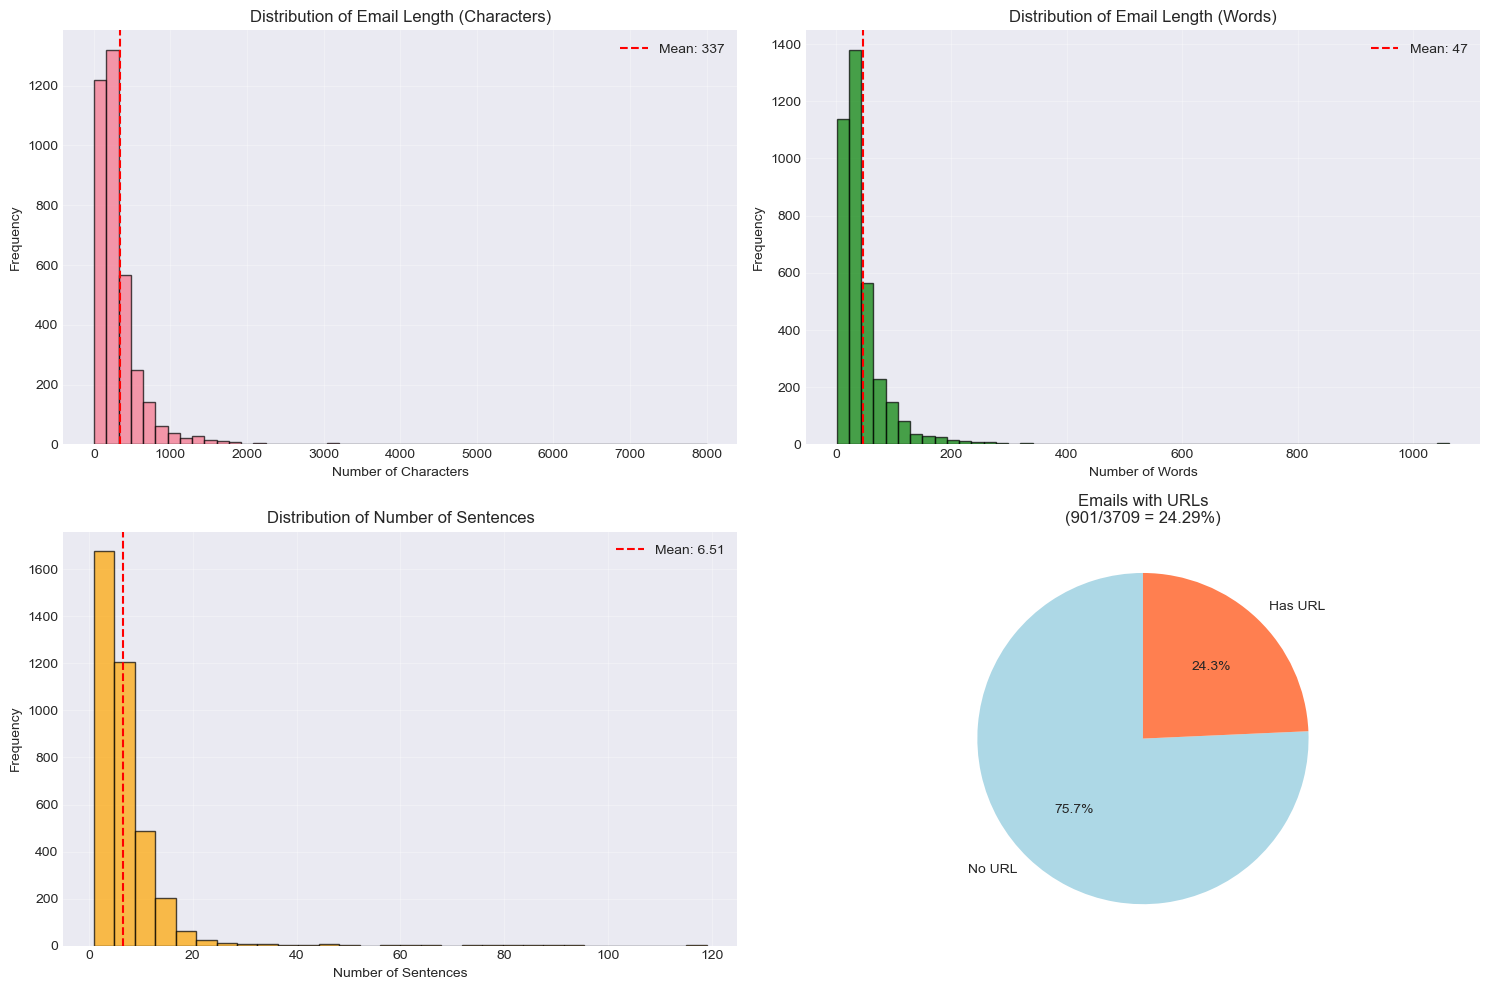


URL Statistics:
Emails with URLs: 901 (24.29%)
Average URLs per email: 0.55
Max URLs in an email: 26


In [8]:
# Visualize text length distributions
fig, axes = plt.subplots(2, 2, figsize=(15, 10))

# Character distribution
axes[0, 0].hist(df['num_characters'], bins=50, edgecolor='black', alpha=0.7)
axes[0, 0].axvline(df['num_characters'].mean(), color='red', linestyle='--', label=f'Mean: {df["num_characters"].mean():.0f}')
axes[0, 0].set_xlabel('Number of Characters')
axes[0, 0].set_ylabel('Frequency')
axes[0, 0].set_title('Distribution of Email Length (Characters)')
axes[0, 0].legend()
axes[0, 0].grid(True, alpha=0.3)

# Word distribution
axes[0, 1].hist(df['num_words'], bins=50, edgecolor='black', alpha=0.7, color='green')
axes[0, 1].axvline(df['num_words'].mean(), color='red', linestyle='--', label=f'Mean: {df["num_words"].mean():.0f}')
axes[0, 1].set_xlabel('Number of Words')
axes[0, 1].set_ylabel('Frequency')
axes[0, 1].set_title('Distribution of Email Length (Words)')
axes[0, 1].legend()
axes[0, 1].grid(True, alpha=0.3)

# Sentence distribution
axes[1, 0].hist(df['num_sentences'], bins=30, edgecolor='black', alpha=0.7, color='orange')
axes[1, 0].axvline(df['num_sentences'].mean(), color='red', linestyle='--', label=f'Mean: {df["num_sentences"].mean():.2f}')
axes[1, 0].set_xlabel('Number of Sentences')
axes[1, 0].set_ylabel('Frequency')
axes[1, 0].set_title('Distribution of Number of Sentences')
axes[1, 0].legend()
axes[1, 0].grid(True, alpha=0.3)

# URL distribution
url_counts = df['has_url'].value_counts()
axes[1, 1].pie(url_counts.values, labels=['No URL', 'Has URL'], autopct='%1.1f%%', 
               colors=['lightblue', 'coral'], startangle=90)
axes[1, 1].set_title(f'Emails with URLs\n({df["has_url"].sum()}/{len(df)} = {df["has_url"].mean()*100:.2f}%)')

plt.tight_layout()
plt.show()

# Print some statistics
print(f"\nURL Statistics:")
print(f"Emails with URLs: {df['has_url'].sum()} ({df['has_url'].mean()*100:.2f}%)")
print(f"Average URLs per email: {df['num_urls'].mean():.2f}")
print(f"Max URLs in an email: {df['num_urls'].max()}")


In [9]:
# Analyze unigrams (single words)
from nltk.corpus import stopwords
import nltk

try:
    nltk.download("stopwords", quiet=True)
    german_stopwords = set(stopwords.words("german"))
except:
    german_stopwords = set()
    print("Using empty stopword list (NLTK stopwords not available)")

# Count vectorizer for unigrams
unigram_vec = CountVectorizer(
    stop_words=list(german_stopwords),
    max_features=50,
    ngram_range=(1, 1)
)
unigram_bow = unigram_vec.fit_transform(df['text_cleaned'])

# Get top words
top_unigrams = pd.DataFrame({
    'word': unigram_vec.get_feature_names_out(),
    'count': unigram_bow.sum(axis=0).A1
}).sort_values(by='count', ascending=False)

print("Top 30 Unigrams (Single Words):")
print("=" * 50)
print(top_unigrams.head(30))


Top 30 Unigrams (Single Words):
       word  count
37      url   2089
30    shoes    690
16       ja    582
24     nike    581
29  schrieb    538
2      ciao    445
33      the    439
28    schon    426
0       air    410
12     gruß    365
19      mal    331
41    watch    310
11     gibt    285
14    immer    272
21     mehr    266
15       is    247
26       on    245
32  sprache    239
45     wort    238
39    viele    233
27    rufen    227
35       to    215
31     shox    206
48      you    204
38       vg    200
25       of    199
47     wäre    193
7      ganz    182
13    größe    182
20      max    170


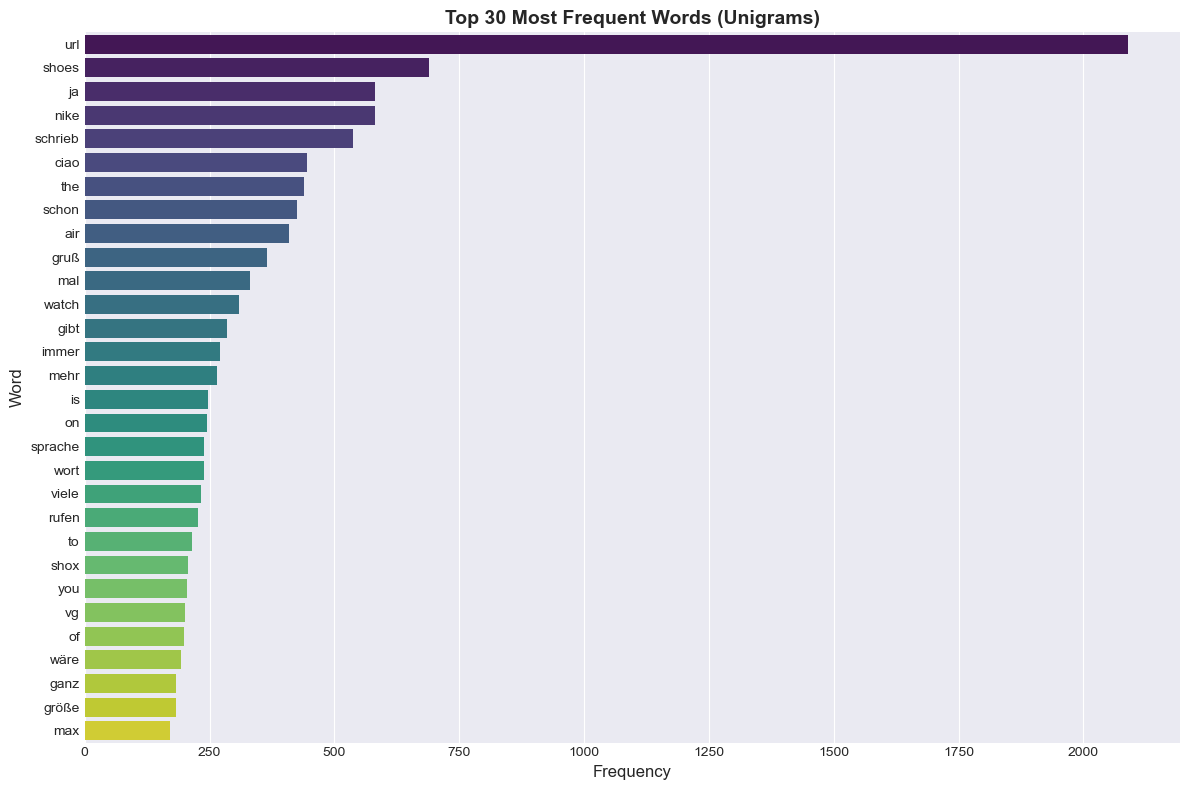

In [10]:
# Visualize top unigrams
plt.figure(figsize=(12, 8))
top_30 = top_unigrams.head(30)
sns.barplot(data=top_30, y='word', x='count', palette='viridis')
plt.xlabel('Frequency', fontsize=12)
plt.ylabel('Word', fontsize=12)
plt.title('Top 30 Most Frequent Words (Unigrams)', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()


Top 30 Bigrams (Two-Word Phrases):
                   bigram  count
26                url url    881
21             shoes nike    195
2                 air max    155
16             nike shoes    145
29            viele größe    144
15               nike air    140
17              nike shox    105
13             mens watch    104
25               tat kund     89
18             non canada     85
4              canada sed     85
20             sed mexico     85
19     popocatepetlum non     85
0               air force     85
14           mexico situm     84
1              air jordan     84
5   censeo popocatepetlum     84
23             situm esse     84
8                esse url     84
6          ceterum censeo     84
27             vg ceterum     79
12               max nike     75
11       leerzeichen akut     67
9                  hmp vg     67
24    spricht leerzeichen     67
3                akut hmp     67
28                 vg url     67
22        shoes wholesale     65
7    deu

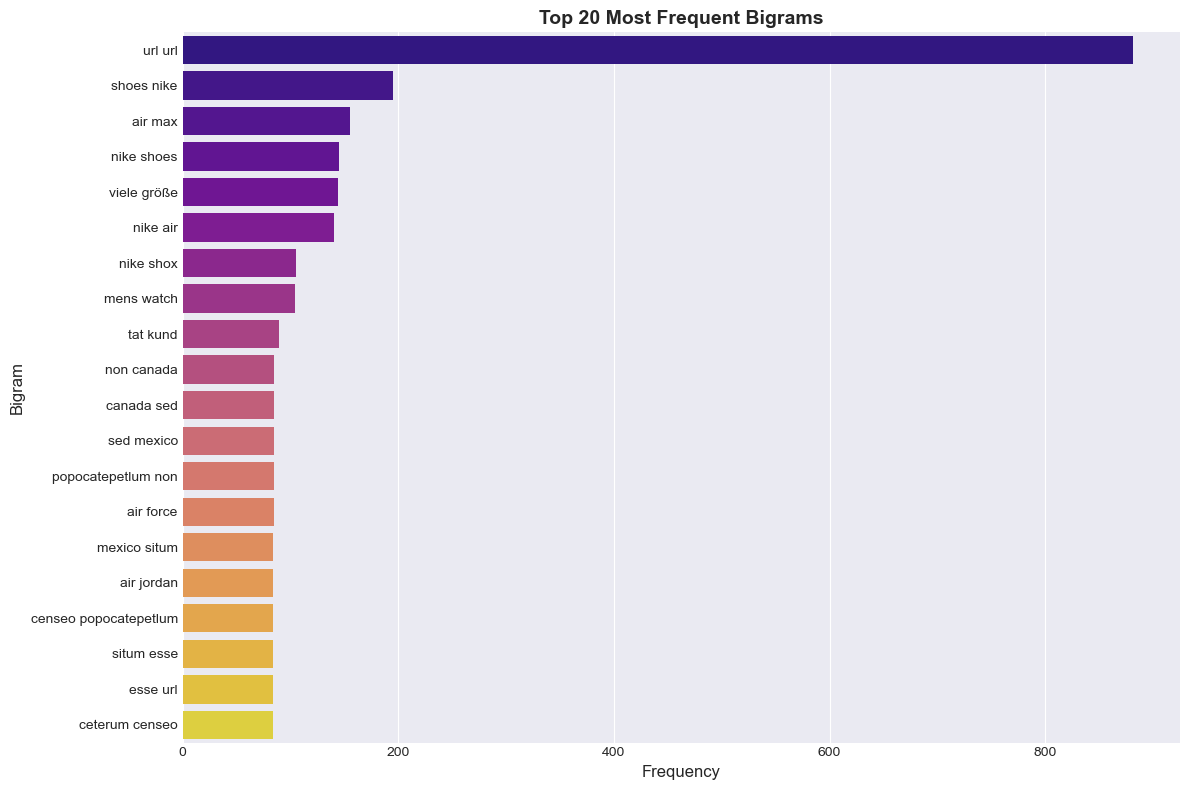

In [11]:
# Analyze bigrams (two-word phrases)
bigram_vec = CountVectorizer(
    stop_words=list(german_stopwords),
    max_features=30,
    ngram_range=(2, 2)
)
bigram_bow = bigram_vec.fit_transform(df['text_cleaned'])

top_bigrams = pd.DataFrame({
    'bigram': bigram_vec.get_feature_names_out(),
    'count': bigram_bow.sum(axis=0).A1
}).sort_values(by='count', ascending=False)

print("Top 30 Bigrams (Two-Word Phrases):")
print("=" * 50)
print(top_bigrams.head(30))

# Visualize
plt.figure(figsize=(12, 8))
sns.barplot(data=top_bigrams.head(20), y='bigram', x='count', palette='plasma')
plt.xlabel('Frequency', fontsize=12)
plt.ylabel('Bigram', fontsize=12)
plt.title('Top 20 Most Frequent Bigrams', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()


In [12]:
# Analyze trigrams
trigram_vec = CountVectorizer(
    stop_words=list(german_stopwords),
    max_features=20,
    ngram_range=(3, 3)
)
trigram_bow = trigram_vec.fit_transform(df['text_cleaned'])

top_trigrams = pd.DataFrame({
    'trigram': trigram_vec.get_feature_names_out(),
    'count': trigram_bow.sum(axis=0).A1
}).sort_values(by='count', ascending=False)

print("Top 20 Trigrams (Three-Word Phrases):")
print("=" * 50)
print(top_trigrams.head(20))


Top 20 Trigrams (Three-Word Phrases):
                          trigram  count
18                    url url url    474
13                 non canada sed     85
2               canada sed mexico     85
14      popocatepetlum non canada     85
10              mexico situm esse     84
3       censeo popocatepetlum non     84
4   ceterum censeo popocatepetlum     84
16                 situm esse url     84
15               sed mexico situm     84
19              vg ceterum censeo     79
11                   nike air max     75
0                    air max nike     75
1                     akut hmp vg     67
8            leerzeichen akut hmp     67
7                      hmp vg url     67
17       spricht leerzeichen akut     67
9                    max nike air     60
6      grimm deutsches wörterbuch     57
5                  de etc sprache     52
12                nike shoes nike     50


### 4.3 Correlation Analysis


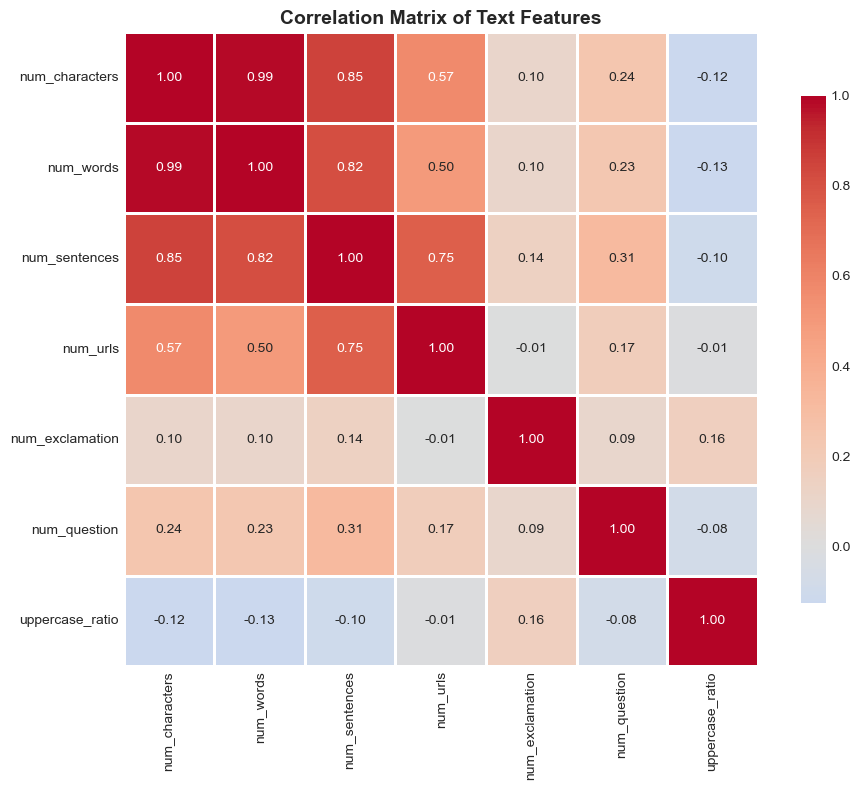

In [13]:
# Correlation matrix of text features
correlation_cols = ['num_characters', 'num_words', 'num_sentences', 'num_urls', 
                    'num_exclamation', 'num_question', 'uppercase_ratio']
corr_matrix = df[correlation_cols].corr()

plt.figure(figsize=(10, 8))
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='coolwarm', center=0,
            square=True, linewidths=1, cbar_kws={"shrink": 0.8})
plt.title('Correlation Matrix of Text Features', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()


### 4.4 Outlier Detection


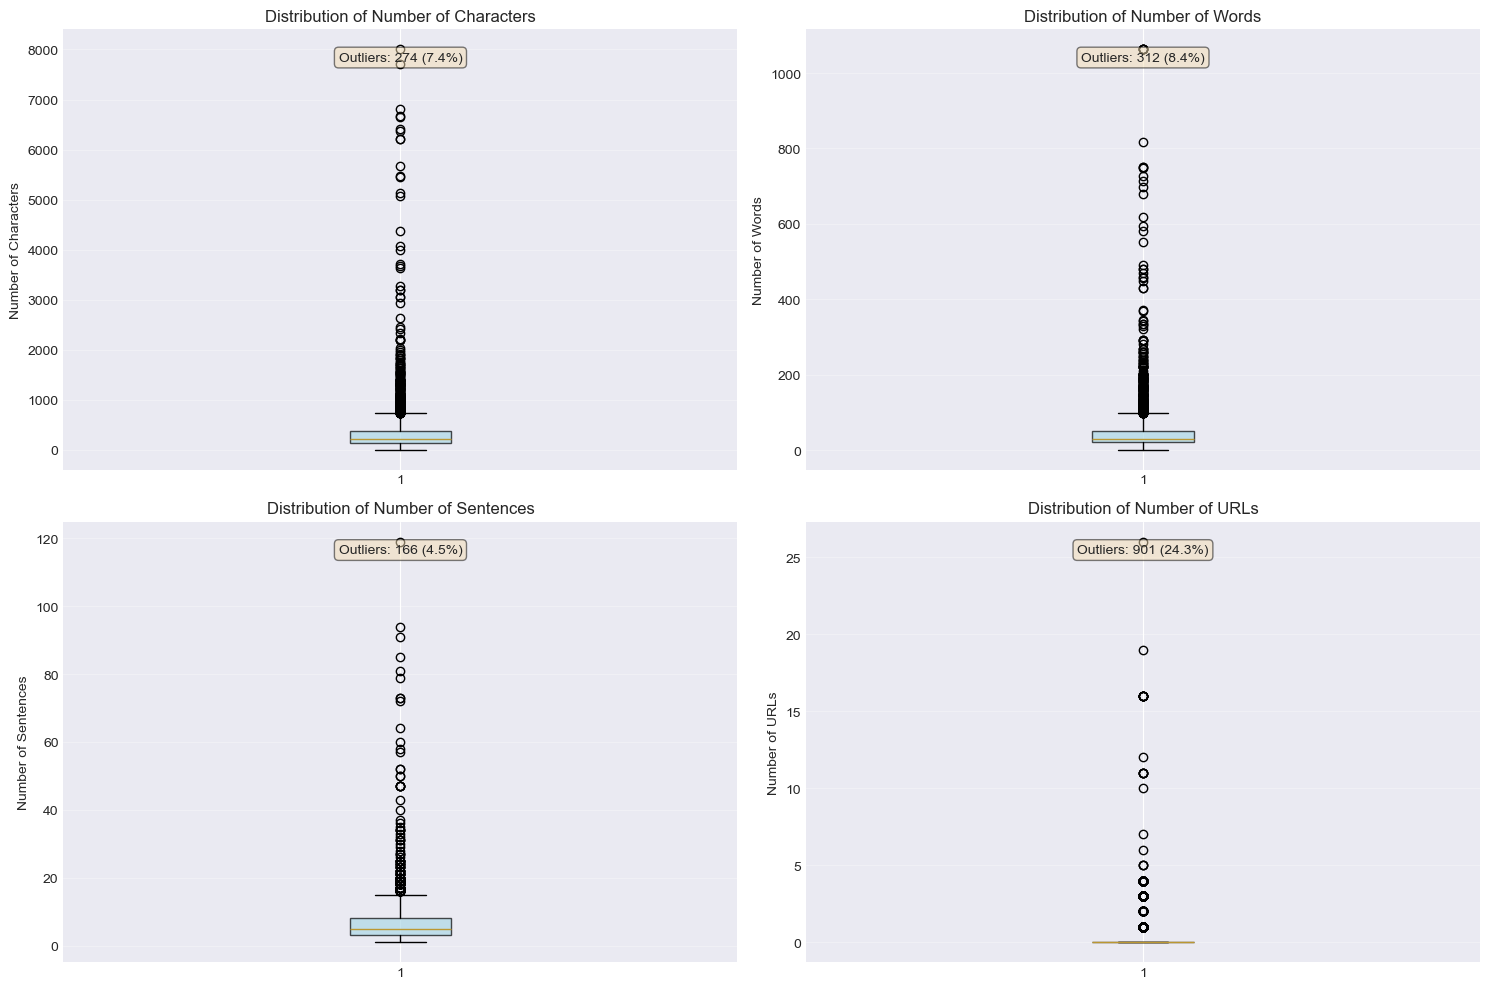

Extreme Outliers (top 5 by character count):

Email 2340:
  Characters: 8003, Words: 1063, URLs: 11
  Preview: www.otha-nahmsejj.dmq wholesale Genossenschaft wholesale - Genossenschaft shoes wholesale.
Genossenschaft shoes: Genossenschaft shox air force1 jordan...

Email 919:
  Characters: 7719, Words: 1063, URLs: 11
  Preview: www.gcrv-qemqtipt.ldg wholesale Tintenklecks wholesale - Tintenklecks shoes wholesale.
Tintenklecks shoes: Tintenklecks shox air force1 jordan TL NZ R...

Email 2702:
  Characters: 6820, Words: 1063, URLs: 11
  Preview: www.bsya-gwfxfahr.dla wholesale Lezit wholesale - Lezit shoes wholesale.
Lezit shoes: Lezit shox air force1 jordan TL NZ R4 Turbo Monster
shoes,Lezit ...

Email 1894:
  Characters: 6673, Words: 1063, URLs: 11
  Preview: www.gcjv-tnvvwkqn.frf wholesale Mogo wholesale - Mogo shoes wholesale.
Mogo shoes: Mogo shox air force1 jordan TL NZ R4 Turbo Monster
shoes,Mogo air m...

Email 2228:
  Characters: 6650, Words: 1063, URLs: 11
  Preview: www.ghdk-w

In [14]:
# Box plots to identify outliers
fig, axes = plt.subplots(2, 2, figsize=(15, 10))

features_to_plot = ['num_characters', 'num_words', 'num_sentences', 'num_urls']
titles = ['Number of Characters', 'Number of Words', 'Number of Sentences', 'Number of URLs']

for idx, (ax, feature, title) in enumerate(zip(axes.flat, features_to_plot, titles)):
    ax.boxplot(df[feature], vert=True, patch_artist=True,
               boxprops=dict(facecolor='lightblue', alpha=0.7))
    ax.set_ylabel(title)
    ax.set_title(f'Distribution of {title}')
    ax.grid(True, alpha=0.3, axis='y')
    
    # Add statistics
    q1 = df[feature].quantile(0.25)
    q3 = df[feature].quantile(0.75)
    iqr = q3 - q1
    outliers = df[(df[feature] < q1 - 1.5*iqr) | (df[feature] > q3 + 1.5*iqr)]
    ax.text(0.5, 0.95, f'Outliers: {len(outliers)} ({len(outliers)/len(df)*100:.1f}%)',
            transform=ax.transAxes, ha='center', va='top',
            bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.5))

plt.tight_layout()
plt.show()

# Show extreme outliers
print("Extreme Outliers (top 5 by character count):")
extreme = df.nlargest(5, 'num_characters')[['num_characters', 'num_words', 'num_urls', 'text']]
for idx, row in extreme.iterrows():
    print(f"\nEmail {idx}:")
    print(f"  Characters: {row['num_characters']}, Words: {row['num_words']}, URLs: {row['num_urls']}")
    print(f"  Preview: {row['text'][:150]}...")


## 5. Train-Test Split (IMPORTANT: Split BEFORE Feature Extraction)


In [ ]:

train_df, test_df = train_test_split(df, test_size=0.2, random_state=42, shuffle=True)

print(f"Training set size: {len(train_df)} ({len(train_df)/len(df)*100:.1f}%)")
print(f"Test set size: {len(test_df)} ({len(test_df)/len(df)*100:.1f}%)")
print(f"\nTraining set preview:")
train_df[['text', 'num_characters', 'num_words', 'has_url', 'text_processed']].head()


Training set size: 2967 (80.0%)
Test set size: 742 (20.0%)

Training set preview:


,text,num_characters,num_words,has_url,text_processed
964,"Am Tue, 3 Aug 2010 01:52:45 -0800 (PST) schrie...",343,31,True,tue aug pst schrieb bruno arnt nix liebe fanta...
507,"FREEMSG: Unsere Aufzeichnungen zeigen an, dass...",180,31,False,freemsg aufzeichnungen zeigen anspruch pfund u...
7,England / Mazedonien - verpassen Sie nicht die...,185,23,False,england mazedonien verpassen tore team nachric...
2123,Fast Food .... Beinahe Nahrung\n\nmfg S. Z.,41,7,False,fast food beinahe nahrung mfg
2833,"Werra Elskemper (Sun, 24. 06. 22 04:10:02 +020...",291,33,True,werra elskemper sun send pix dsf oliver oliver...


## 6. Feature Extraction with TF-IDF (Fit ONLY on Training Data)


In [ ]:
# Define consistent TF-IDF configuration
TFIDF_MAX_FEATURES = 3000
TFIDF_NGRAM_RANGE = (1, 2)  


tfidf_vectorizer = TfidfVectorizer(
    max_features=TFIDF_MAX_FEATURES,
    ngram_range=TFIDF_NGRAM_RANGE,
    stop_words=list(german_stopwords),
    min_df=2, 
    max_df=0.95  
)

print("Fitting TF-IDF vectorizer on training data...")
X_train_tfidf = tfidf_vectorizer.fit_transform(train_df['text_processed'])
print(f"Training TF-IDF matrix shape: {X_train_tfidf.shape}")


print("\nTransforming test data with fitted vectorizer...")
X_test_tfidf = tfidf_vectorizer.transform(test_df['text_processed'])
print(f"Test TF-IDF matrix shape: {X_test_tfidf.shape}")

print(f"\nFeature names (first 20): {list(tfidf_vectorizer.get_feature_names_out()[:20])}")


Fitting TF-IDF vectorizer on training data...
Training TF-IDF matrix shape: (2967, 3000)

Transforming test data with fitted vectorizer...
Test TF-IDF matrix shape: (742, 3000)

Feature names (first 20): ['aaa', 'aaa replica', 'abend', 'abermals', 'abgesehen', 'abgetrennt', 'abmelden', 'about', 'absicht', 'ac', 'adam', 'address', 'address works', 'adj', 'adjektiv', 'adolf', 'af', 'afghanistan', 'age', 'ah']


## 7. Dimensionality Reduction for Visualization and Clustering


Applying TruncatedSVD to reduce from 3000 to 100 dimensions...
Explained variance ratio: 0.2899 (28.99%)
Reduced training matrix shape: (2967, 100)
Reduced test matrix shape: (742, 100)


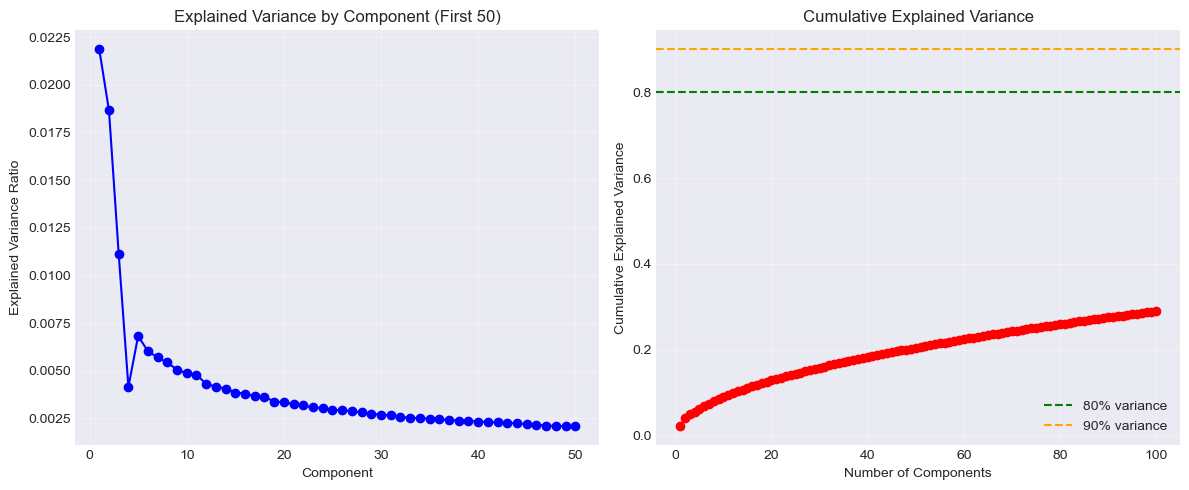

In [ ]:

N_COMPONENTS = 100

print(f"Applying TruncatedSVD to reduce from {X_train_tfidf.shape[1]} to {N_COMPONENTS} dimensions...")
svd = TruncatedSVD(n_components=N_COMPONENTS, random_state=42)
X_train_reduced = svd.fit_transform(X_train_tfidf)


X_test_reduced = svd.transform(X_test_tfidf)

print(f"Explained variance ratio: {svd.explained_variance_ratio_.sum():.4f} ({svd.explained_variance_ratio_.sum()*100:.2f}%)")
print(f"Reduced training matrix shape: {X_train_reduced.shape}")
print(f"Reduced test matrix shape: {X_test_reduced.shape}")


plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.plot(range(1, min(50, N_COMPONENTS)+1), svd.explained_variance_ratio_[:50], 'bo-')
plt.xlabel('Component')
plt.ylabel('Explained Variance Ratio')
plt.title('Explained Variance by Component (First 50)')
plt.grid(True, alpha=0.3)

plt.subplot(1, 2, 2)
cumulative_var = np.cumsum(svd.explained_variance_ratio_)
plt.plot(range(1, N_COMPONENTS+1), cumulative_var, 'ro-')
plt.xlabel('Number of Components')
plt.ylabel('Cumulative Explained Variance')
plt.title('Cumulative Explained Variance')
plt.axhline(y=0.8, color='g', linestyle='--', label='80% variance')
plt.axhline(y=0.9, color='orange', linestyle='--', label='90% variance')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


2D PCA explained variance: 0.1453 (14.53%)


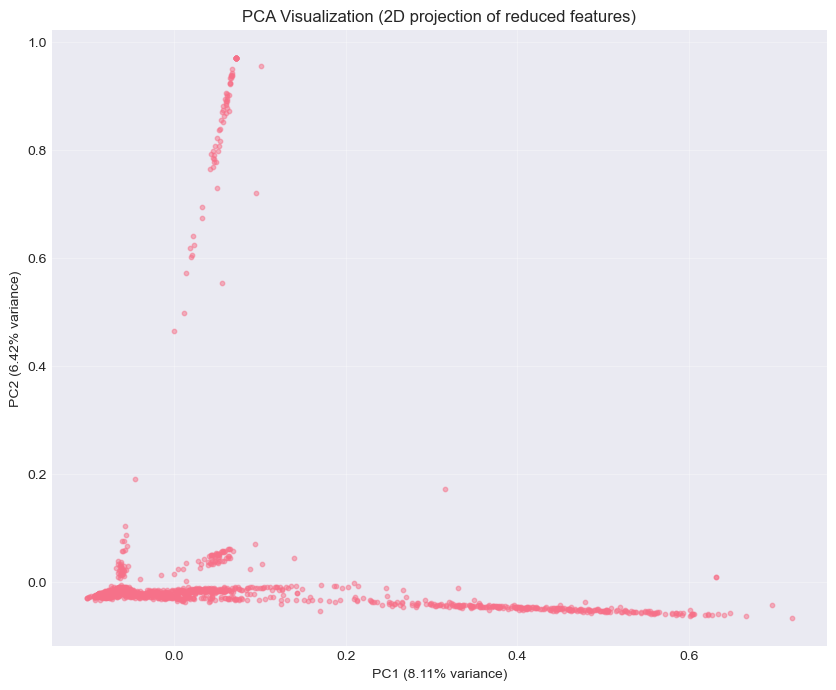

In [ ]:

pca_2d = PCA(n_components=2, random_state=42)
X_train_pca_2d = pca_2d.fit_transform(X_train_reduced)

print(f"2D PCA explained variance: {pca_2d.explained_variance_ratio_.sum():.4f} ({pca_2d.explained_variance_ratio_.sum()*100:.2f}%)")

plt.figure(figsize=(10, 8))
plt.scatter(X_train_pca_2d[:, 0], X_train_pca_2d[:, 1], s=10, alpha=0.5)
plt.xlabel(f'PC1 ({pca_2d.explained_variance_ratio_[0]*100:.2f}% variance)')
plt.ylabel(f'PC2 ({pca_2d.explained_variance_ratio_[1]*100:.2f}% variance)')
plt.title('PCA Visualization (2D projection of reduced features)')
plt.grid(True, alpha=0.3)
plt.show()


## 8. Clustering Analysis


### 8.1 Finding Optimal Number of Clusters


Evaluating different numbers of clusters...
K=2: Inertia=777.99, Silhouette=0.1087, DB=1.7233
K=3: Inertia=764.04, Silhouette=0.1157, DB=1.5214
K=4: Inertia=711.20, Silhouette=0.1437, DB=1.3755
K=5: Inertia=679.52, Silhouette=0.1586, DB=2.0991
K=6: Inertia=677.46, Silhouette=0.0797, DB=2.0508
K=7: Inertia=651.73, Silhouette=0.1626, DB=2.4197
K=8: Inertia=646.48, Silhouette=0.1689, DB=2.0508
K=9: Inertia=629.29, Silhouette=0.1292, DB=2.0491
K=10: Inertia=634.92, Silhouette=0.0576, DB=2.0551
K=11: Inertia=610.04, Silhouette=0.1028, DB=2.0767
K=12: Inertia=606.24, Silhouette=0.1445, DB=1.4664
K=13: Inertia=597.65, Silhouette=0.1488, DB=1.5182
K=14: Inertia=583.69, Silhouette=0.1121, DB=1.2982


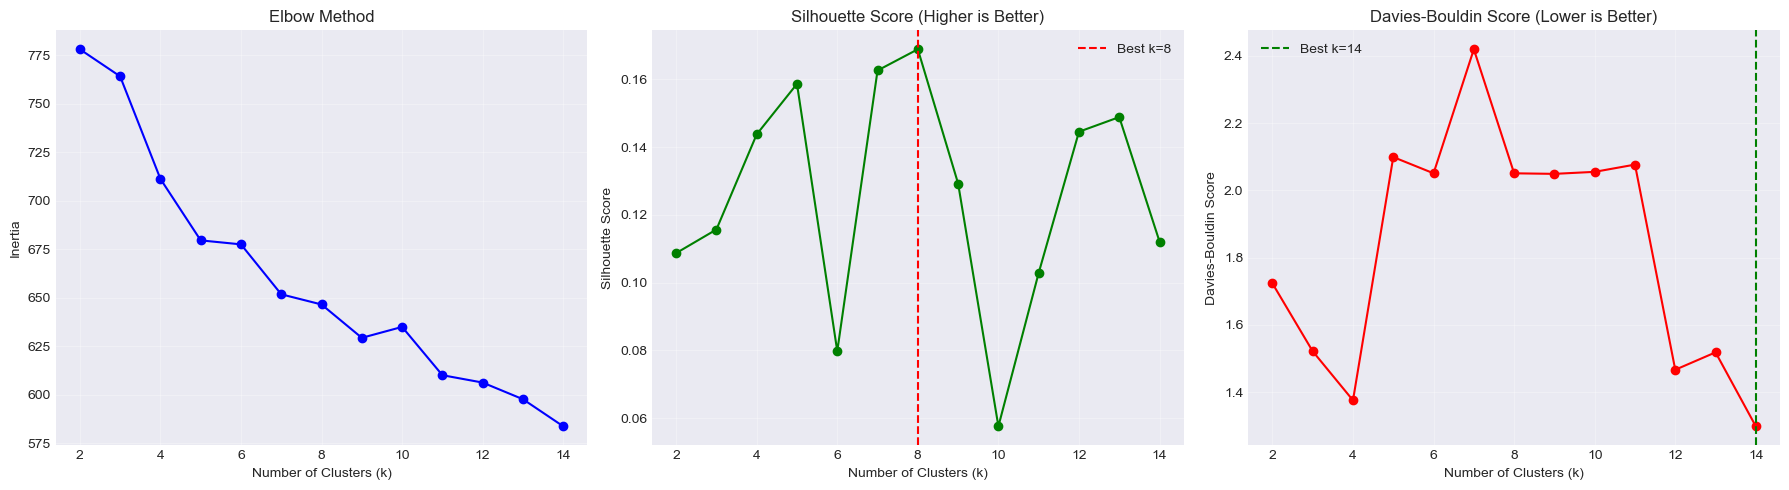


Best k by Silhouette Score: 8
Best k by Davies-Bouldin Score: 14


In [19]:
# Elbow method and Silhouette analysis
K_range = range(2, 15)
inertias = []
silhouette_scores = []
davies_bouldin_scores = []

print("Evaluating different numbers of clusters...")
for k in K_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = km.fit_predict(X_train_reduced)
    
    inertias.append(km.inertia_)
    silhouette_scores.append(silhouette_score(X_train_reduced, labels))
    davies_bouldin_scores.append(davies_bouldin_score(X_train_reduced, labels))
    print(f"K={k}: Inertia={km.inertia_:.2f}, Silhouette={silhouette_scores[-1]:.4f}, DB={davies_bouldin_scores[-1]:.4f}")

# Visualize
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Elbow method
axes[0].plot(K_range, inertias, 'bo-')
axes[0].set_xlabel('Number of Clusters (k)')
axes[0].set_ylabel('Inertia')
axes[0].set_title('Elbow Method')
axes[0].grid(True, alpha=0.3)

# Silhouette scores (higher is better)
axes[1].plot(K_range, silhouette_scores, 'go-')
axes[1].set_xlabel('Number of Clusters (k)')
axes[1].set_ylabel('Silhouette Score')
axes[1].set_title('Silhouette Score (Higher is Better)')
axes[1].grid(True, alpha=0.3)
best_k_sil = K_range[np.argmax(silhouette_scores)]
axes[1].axvline(x=best_k_sil, color='r', linestyle='--', label=f'Best k={best_k_sil}')
axes[1].legend()

# Davies-Bouldin scores (lower is better)
axes[2].plot(K_range, davies_bouldin_scores, 'ro-')
axes[2].set_xlabel('Number of Clusters (k)')
axes[2].set_ylabel('Davies-Bouldin Score')
axes[2].set_title('Davies-Bouldin Score (Lower is Better)')
axes[2].grid(True, alpha=0.3)
best_k_db = K_range[np.argmin(davies_bouldin_scores)]
axes[2].axvline(x=best_k_db, color='g', linestyle='--', label=f'Best k={best_k_db}')
axes[2].legend()

plt.tight_layout()
plt.show()

print(f"\nBest k by Silhouette Score: {best_k_sil}")
print(f"Best k by Davies-Bouldin Score: {best_k_db}")


In [ ]:

OPTIMAL_K = best_k_sil  

print(f"Using k={OPTIMAL_K} clusters for final clustering")


Using k=8 clusters for final clustering


### 8.2 Apply K-Means Clustering


In [21]:
# Apply K-Means clustering on training data
kmeans = KMeans(n_clusters=OPTIMAL_K, random_state=42, n_init=10)
train_clusters = kmeans.fit_predict(X_train_reduced)

train_df['cluster'] = train_clusters

# Calculate cluster metrics
silhouette_avg = silhouette_score(X_train_reduced, train_clusters)
db_score = davies_bouldin_score(X_train_reduced, train_clusters)
ch_score = calinski_harabasz_score(X_train_reduced, train_clusters)

print(f"Clustering Results (k={OPTIMAL_K}):")
print(f"  Silhouette Score: {silhouette_avg:.4f}")
print(f"  Davies-Bouldin Score: {db_score:.4f}")
print(f"  Calinski-Harabasz Score: {ch_score:.4f}")
print(f"\nCluster sizes:")
print(train_df['cluster'].value_counts().sort_index())


Clustering Results (k=8):
  Silhouette Score: 0.1689
  Davies-Bouldin Score: 2.0508
  Calinski-Harabasz Score: 125.0307

Cluster sizes:
cluster
0      56
1     371
2    2105
3      19
4      28
5      17
6     299
7      72
Name: count, dtype: int64


### 8.3 Cluster Analysis and Interpretation


In [ ]:

import numpy as np

def analyze_cluster(cluster_id, df, feature_names, X_tfidf_matrix, top_n=20):
    """Analyze characteristics of a specific cluster"""
    cluster_data = df[df['cluster'] == cluster_id]
    
   
    cluster_mask = df['cluster'] == cluster_id
    cluster_positions = np.where(cluster_mask)[0].tolist()
    
   
    cluster_tfidf = X_tfidf_matrix[cluster_positions]
    
   
    mean_scores = cluster_tfidf.mean(axis=0).A1
    top_indices = mean_scores.argsort()[-top_n:][::-1]
    top_terms = [feature_names[i] for i in top_indices]
    top_scores = mean_scores[top_indices]
    
    return {
        'size': len(cluster_data),
        'avg_chars': cluster_data['num_characters'].mean(),
        'avg_words': cluster_data['num_words'].mean(),
        'url_rate': cluster_data['has_url'].mean(),
        'avg_urls': cluster_data['num_urls'].mean(),
        'avg_exclamation': cluster_data['num_exclamation'].mean(),
        'top_terms': top_terms,
        'top_scores': top_scores,
        'sample_texts': cluster_data['text'].head(3).tolist()
    }


print("=" * 80)
print("RUNNING CLUSTER ANALYSIS")
print("=" * 80)

feature_names = tfidf_vectorizer.get_feature_names_out()
cluster_analysis = {}

for cluster_id in sorted(train_df['cluster'].unique()):
    print(f"\nAnalyzing cluster {cluster_id}...")
    try:
        analysis = analyze_cluster(cluster_id, train_df, feature_names, X_train_tfidf)
        cluster_analysis[cluster_id] = analysis
        print(f"  ✓ Success! Size: {analysis['size']} emails, URL rate: {analysis['url_rate']*100:.1f}%")
    except Exception as e:
        print(f"  ✗ Error: {type(e).__name__}: {e}")
        import traceback
        traceback.print_exc()

print(f"\n{'='*80}")
print(f"Analysis complete! Processed {len(cluster_analysis)} clusters")
print(f"{'='*80}")


if cluster_analysis:
    print(f"\n✓ cluster_analysis is now populated with {len(cluster_analysis)} clusters")
    print(f"Cluster IDs: {sorted(cluster_analysis.keys())}")
else:
    print("\n✗ cluster_analysis is still empty - check errors above")

RUNNING CLUSTER ANALYSIS

Analyzing cluster 0...
  ✓ Success! Size: 56 emails, URL rate: 100.0%

Analyzing cluster 1...
  ✓ Success! Size: 371 emails, URL rate: 13.2%

Analyzing cluster 2...
  ✓ Success! Size: 2105 emails, URL rate: 11.9%

Analyzing cluster 3...
  ✓ Success! Size: 19 emails, URL rate: 15.8%

Analyzing cluster 4...
  ✓ Success! Size: 28 emails, URL rate: 0.0%

Analyzing cluster 5...
  ✓ Success! Size: 17 emails, URL rate: 0.0%

Analyzing cluster 6...
  ✓ Success! Size: 299 emails, URL rate: 100.0%

Analyzing cluster 7...
  ✓ Success! Size: 72 emails, URL rate: 100.0%

Analysis complete! Processed 8 clusters

✓ cluster_analysis is now populated with 8 clusters
Cluster IDs: [np.int32(0), np.int32(1), np.int32(2), np.int32(3), np.int32(4), np.int32(5), np.int32(6), np.int32(7)]


URL rates: [np.float64(100.0), np.float64(13.20754716981132), np.float64(11.923990498812351), np.float64(15.789473684210526), np.float64(0.0), np.float64(0.0), np.float64(100.0), np.float64(100.0)]
Avg words: [np.float64(43.07142857142857), np.float64(23.371967654986523), np.float64(50.6479809976247), np.float64(59.8421052631579), np.float64(22.785714285714285), np.float64(36.0), np.float64(56.23745819397993), np.float64(38.611111111111114)]
Avg exclamation: [np.float64(1.1428571428571428), np.float64(0.6522911051212938), np.float64(0.25748218527315914), np.float64(0.10526315789473684), np.float64(1.7142857142857142), np.float64(0.35294117647058826), np.float64(0.11036789297658862), np.float64(0.09722222222222222)]


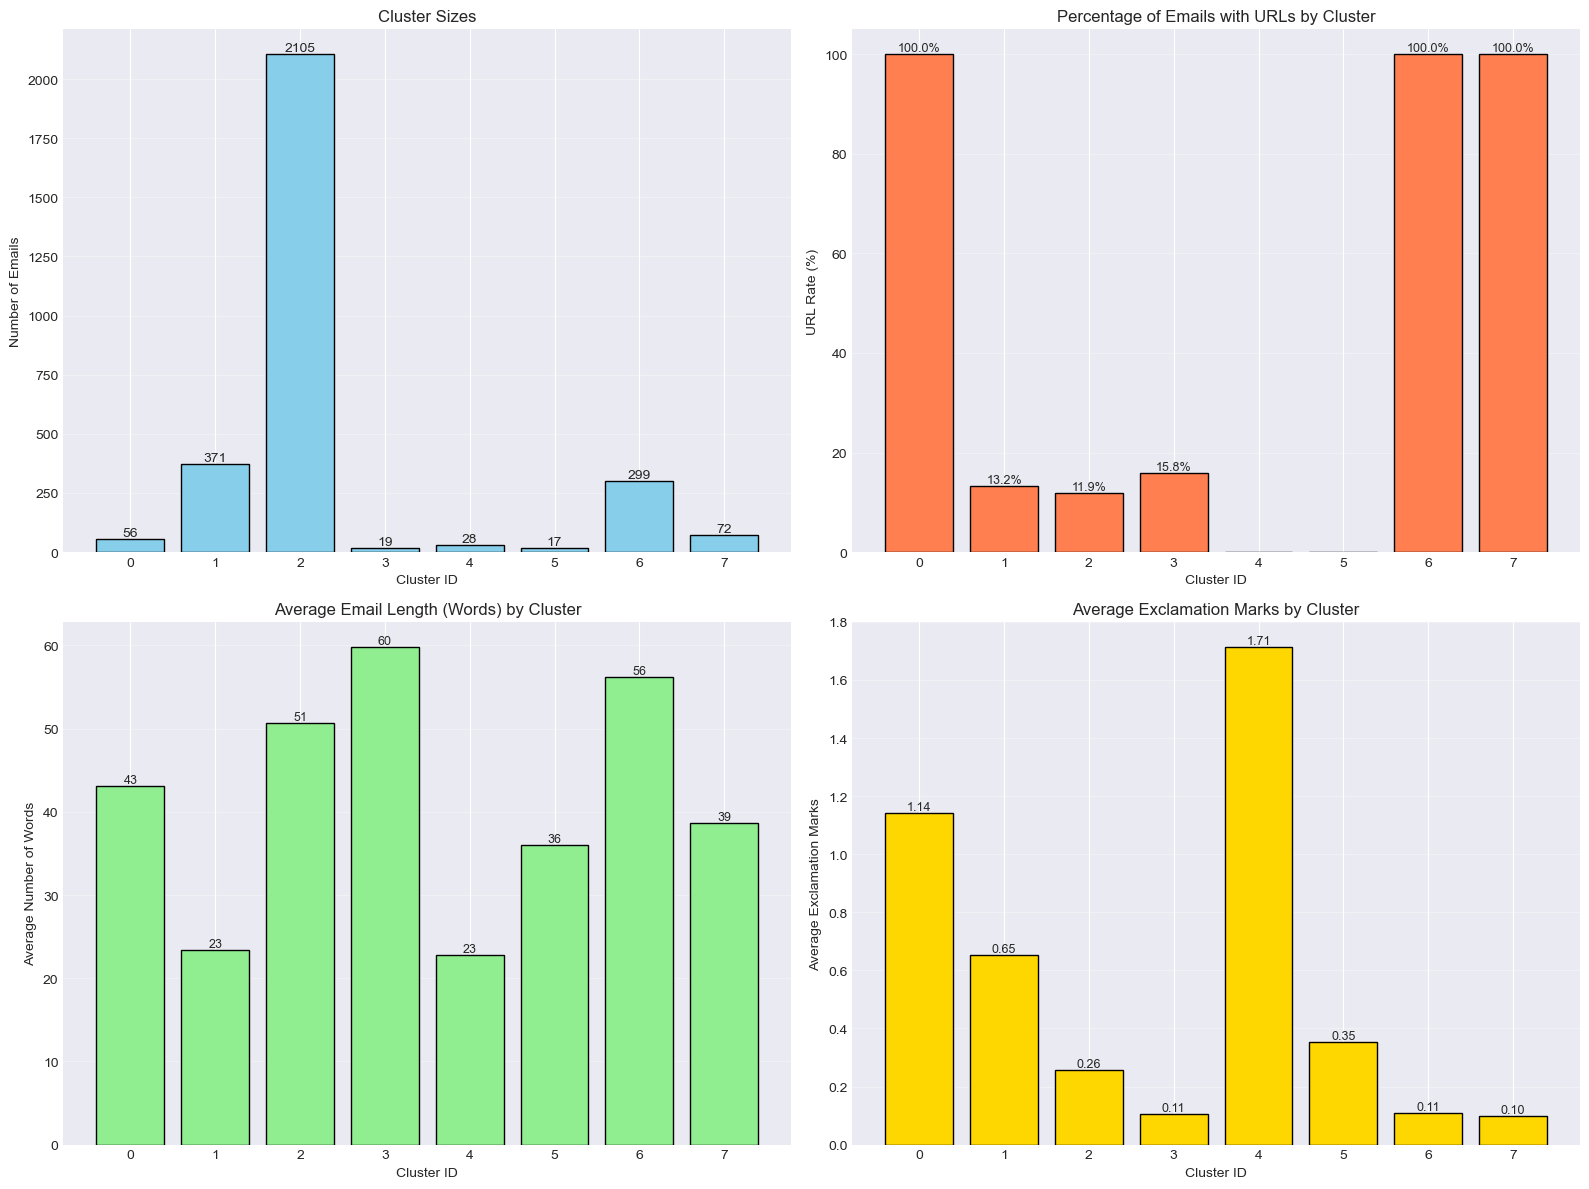

In [23]:
# # Visualize cluster characteristics
# fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# # Cluster sizes
# cluster_sizes = train_df['cluster'].value_counts().sort_index()
# axes[0, 0].bar(cluster_sizes.index, cluster_sizes.values, color='skyblue', edgecolor='black')
# axes[0, 0].set_xlabel('Cluster ID')
# axes[0, 0].set_ylabel('Number of Emails')
# axes[0, 0].set_title('Cluster Sizes')
# axes[0, 0].grid(True, alpha=0.3, axis='y')
# for i, v in enumerate(cluster_sizes.values):
#     axes[0, 0].text(cluster_sizes.index[i], v, str(v), ha='center', va='bottom')

# # URL rate by cluster
# url_rates = [cluster_analysis[i]['url_rate']*100 for i in sorted(cluster_analysis.keys())]
# axes[0, 1].bar(range(len(url_rates)), url_rates, color='coral', edgecolor='black')
# axes[0, 1].set_xlabel('Cluster ID')
# axes[0, 1].set_ylabel('URL Rate (%)')
# axes[0, 1].set_title('Percentage of Emails with URLs by Cluster')
# axes[0, 1].set_xticks(range(len(url_rates)))
# axes[0, 1].set_xticklabels(sorted(cluster_analysis.keys()))
# axes[0, 1].grid(True, alpha=0.3, axis='y')

# # Average words per cluster
# avg_words = [cluster_analysis[i]['avg_words'] for i in sorted(cluster_analysis.keys())]
# axes[1, 0].bar(range(len(avg_words)), avg_words, color='lightgreen', edgecolor='black')
# axes[1, 0].set_xlabel('Cluster ID')
# axes[1, 0].set_ylabel('Average Number of Words')
# axes[1, 0].set_title('Average Email Length (Words) by Cluster')
# axes[1, 0].set_xticks(range(len(avg_words)))
# axes[1, 0].set_xticklabels(sorted(cluster_analysis.keys()))
# axes[1, 0].grid(True, alpha=0.3, axis='y')

# # Average exclamation marks
# avg_excl = [cluster_analysis[i]['avg_exclamation'] for i in sorted(cluster_analysis.keys())]
# axes[1, 1].bar(range(len(avg_excl)), avg_excl, color='gold', edgecolor='black')
# axes[1, 1].set_xlabel('Cluster ID')
# axes[1, 1].set_ylabel('Average Exclamation Marks')
# axes[1, 1].set_title('Average Exclamation Marks by Cluster')
# axes[1, 1].set_xticks(range(len(avg_excl)))
# axes[1, 1].set_xticklabels(sorted(cluster_analysis.keys()))
# axes[1, 1].grid(True, alpha=0.3, axis='y')

# plt.tight_layout()
# plt.show()


# Visualize cluster characteristics - FIXED VERSION
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# Cluster sizes
cluster_sizes = train_df['cluster'].value_counts().sort_index()
axes[0, 0].bar(cluster_sizes.index, cluster_sizes.values, color='skyblue', edgecolor='black')
axes[0, 0].set_xlabel('Cluster ID')
axes[0, 0].set_ylabel('Number of Emails')
axes[0, 0].set_title('Cluster Sizes')
axes[0, 0].grid(True, alpha=0.3, axis='y')
for i, v in enumerate(cluster_sizes.values):
    axes[0, 0].text(cluster_sizes.index[i], v, str(v), ha='center', va='bottom')

# Check if cluster_analysis has data
if cluster_analysis and len(cluster_analysis) > 0:
    sorted_cluster_ids = sorted(cluster_analysis.keys())
    
    # Extract data safely
    url_rates = [cluster_analysis[i].get('url_rate', 0) * 100 for i in sorted_cluster_ids]
    avg_words = [cluster_analysis[i].get('avg_words', 0) for i in sorted_cluster_ids]
    avg_excl = [cluster_analysis[i].get('avg_exclamation', 0) for i in sorted_cluster_ids]
    
    # Debug: Print values to see what we're plotting
    print(f"URL rates: {url_rates}")
    print(f"Avg words: {avg_words}")
    print(f"Avg exclamation: {avg_excl}")
    
    # URL rate by cluster
    axes[0, 1].bar(range(len(url_rates)), url_rates, color='coral', edgecolor='black')
    axes[0, 1].set_xlabel('Cluster ID')
    axes[0, 1].set_ylabel('URL Rate (%)')
    axes[0, 1].set_title('Percentage of Emails with URLs by Cluster')
    axes[0, 1].set_xticks(range(len(url_rates)))
    axes[0, 1].set_xticklabels(sorted_cluster_ids)
    axes[0, 1].grid(True, alpha=0.3, axis='y')
    # Add value labels on bars
    for i, v in enumerate(url_rates):
        if v > 0:  # Only label if value > 0
            axes[0, 1].text(i, v, f'{v:.1f}%', ha='center', va='bottom', fontsize=9)
    
    # Average words per cluster
    axes[1, 0].bar(range(len(avg_words)), avg_words, color='lightgreen', edgecolor='black')
    axes[1, 0].set_xlabel('Cluster ID')
    axes[1, 0].set_ylabel('Average Number of Words')
    axes[1, 0].set_title('Average Email Length (Words) by Cluster')
    axes[1, 0].set_xticks(range(len(avg_words)))
    axes[1, 0].set_xticklabels(sorted_cluster_ids)
    axes[1, 0].grid(True, alpha=0.3, axis='y')
    # Add value labels on bars
    for i, v in enumerate(avg_words):
        if v > 0:
            axes[1, 0].text(i, v, f'{v:.0f}', ha='center', va='bottom', fontsize=9)
    
    # Average exclamation marks
    axes[1, 1].bar(range(len(avg_excl)), avg_excl, color='gold', edgecolor='black')
    axes[1, 1].set_xlabel('Cluster ID')
    axes[1, 1].set_ylabel('Average Exclamation Marks')
    axes[1, 1].set_title('Average Exclamation Marks by Cluster')
    axes[1, 1].set_xticks(range(len(avg_excl)))
    axes[1, 1].set_xticklabels(sorted_cluster_ids)
    axes[1, 1].grid(True, alpha=0.3, axis='y')
    # Add value labels on bars
    for i, v in enumerate(avg_excl):
        if v > 0:
            axes[1, 1].text(i, v, f'{v:.2f}', ha='center', va='bottom', fontsize=9)
else:
    print("Warning: cluster_analysis is empty or not populated!")

plt.tight_layout()
plt.show()

In [24]:
# Quick diagnostic
print("Checking prerequisites...")
print(f"1. train_df has 'cluster' column: {'cluster' in train_df.columns}")
if 'cluster' in train_df.columns:
    print(f"   Unique clusters: {sorted(train_df['cluster'].unique())}")
print(f"2. X_train_tfidf exists: {'X_train_tfidf' in globals()}")
if 'X_train_tfidf' in globals():
    print(f"   X_train_tfidf shape: {X_train_tfidf.shape}")
print(f"3. tfidf_vectorizer exists: {'tfidf_vectorizer' in globals()}")
print(f"4. cluster_analysis exists: {'cluster_analysis' in globals()}")
if 'cluster_analysis' in globals():
    print(f"   cluster_analysis length: {len(cluster_analysis) if cluster_analysis else 0}")

Checking prerequisites...
1. train_df has 'cluster' column: True
   Unique clusters: [np.int32(0), np.int32(1), np.int32(2), np.int32(3), np.int32(4), np.int32(5), np.int32(6), np.int32(7)]
2. X_train_tfidf exists: True
   X_train_tfidf shape: (2967, 3000)
3. tfidf_vectorizer exists: True
4. cluster_analysis exists: True
   cluster_analysis length: 8


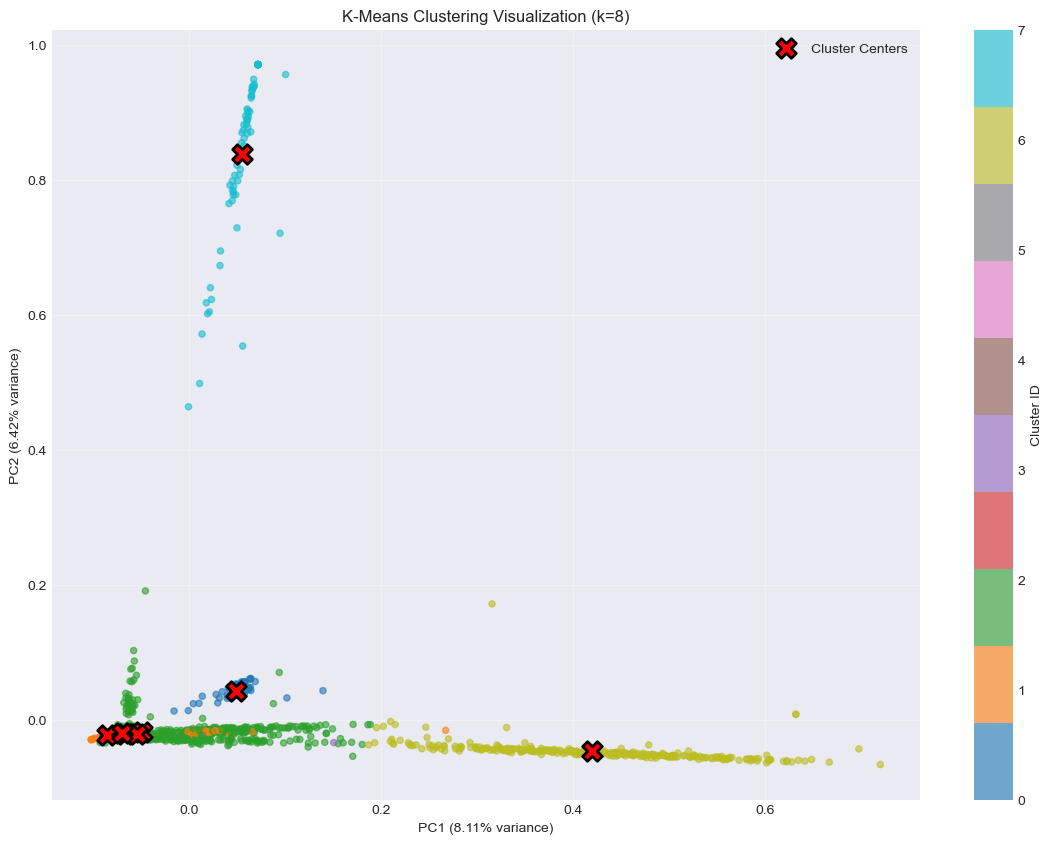

In [25]:
# Visualize clusters in 2D space
plt.figure(figsize=(14, 10))
scatter = plt.scatter(X_train_pca_2d[:, 0], X_train_pca_2d[:, 1], 
                     c=train_df['cluster'], cmap='tab10', s=20, alpha=0.6)
plt.colorbar(scatter, label='Cluster ID')
plt.xlabel(f'PC1 ({pca_2d.explained_variance_ratio_[0]*100:.2f}% variance)')
plt.ylabel(f'PC2 ({pca_2d.explained_variance_ratio_[1]*100:.2f}% variance)')
plt.title(f'K-Means Clustering Visualization (k={OPTIMAL_K})')

# Add cluster centers
cluster_centers_2d = pca_2d.transform(kmeans.cluster_centers_)
plt.scatter(cluster_centers_2d[:, 0], cluster_centers_2d[:, 1], 
           marker='X', s=200, c='red', edgecolors='black', linewidths=2, label='Cluster Centers')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()


In [26]:
# Based on cluster analysis, identify which clusters are likely spam
# Criteria: High URL rate, high exclamation marks, suspicious keywords
# This should be adjusted based on your cluster analysis results

# Calculate spam indicators for each cluster
spam_scores = {}
for cluster_id in cluster_analysis.keys():
    score = 0
    analysis = cluster_analysis[cluster_id]
    
    # URL rate (spam often has URLs)
    if analysis['url_rate'] > 0.3:  # More than 30% have URLs
        score += 2
    elif analysis['url_rate'] > 0.1:
        score += 1
    
    # Exclamation marks (spam often uses many)
    if analysis['avg_exclamation'] > 2:
        score += 1
    
    # Check for spam keywords in top terms
    spam_keywords = ['url', 'klicken', 'sofort', 'gewinnen', 'kostenlos', 'gewonnen', 
                     'gesperrt', 'verifizieren', 'bestätigen', 'konto', 'rabatt']
    spam_terms_count = sum(1 for term in analysis['top_terms'] if any(kw in term.lower() for kw in spam_keywords))
    if spam_terms_count >= 3:
        score += 2
    elif spam_terms_count >= 1:
        score += 1
    
    spam_scores[cluster_id] = score

print("Spam Score by Cluster (higher = more likely spam):")
for cluster_id, score in sorted(spam_scores.items(), key=lambda x: x[1], reverse=True):
    print(f"  Cluster {cluster_id}: {score} points")
    print(f"    - URL rate: {cluster_analysis[cluster_id]['url_rate']*100:.1f}%")
    print(f"    - Avg exclamation: {cluster_analysis[cluster_id]['avg_exclamation']:.2f}")
    print(f"    - Top terms: {', '.join(cluster_analysis[cluster_id]['top_terms'][:5])}")

# Assign labels: clusters with score >= 3 are likely spam
spam_clusters = [cluster_id for cluster_id, score in spam_scores.items() if score >= 3]
print(f"\nClusters identified as SPAM: {spam_clusters}")

# Create labels: 1 = spam, 0 = ham
train_df['label'] = train_df['cluster'].apply(lambda x: 1 if x in spam_clusters else 0)

print(f"\nLabel distribution in training set:")
print(train_df['label'].value_counts())
print(f"\nSpam rate: {train_df['label'].mean()*100:.2f}%")


Spam Score by Cluster (higher = more likely spam):
  Cluster 0: 4 points
    - URL rate: 100.0%
    - Avg exclamation: 1.14
    - Top terms: hmp vg, vg url, hmp, akut, akut hmp
  Cluster 6: 3 points
    - URL rate: 100.0%
    - Avg exclamation: 0.11
    - Top terms: url, url url, ciao, schrieb, fri
  Cluster 7: 3 points
    - URL rate: 100.0%
    - Avg exclamation: 0.10
    - Top terms: popocatepetlum non, ceterum, non, canada sed, sed mexico
  Cluster 1: 2 points
    - URL rate: 13.2%
    - Avg exclamation: 0.65
    - Top terms: rufen, txt, ur, stop, text
  Cluster 2: 2 points
    - URL rate: 11.9%
    - Avg exclamation: 0.26
    - Top terms: gruß, mal, größe, url, wort
  Cluster 3: 1 points
    - URL rate: 15.8%
    - Avg exclamation: 0.11
    - Top terms: ff, pgp key, key rsa, rsa bd, rsa
  Cluster 4: 1 points
    - URL rate: 0.0%
    - Avg exclamation: 1.71
    - Top terms: urgent, preis, rufen, gültig, gültig stunden
  Cluster 5: 0 points
    - URL rate: 0.0%
    - Avg exclamation

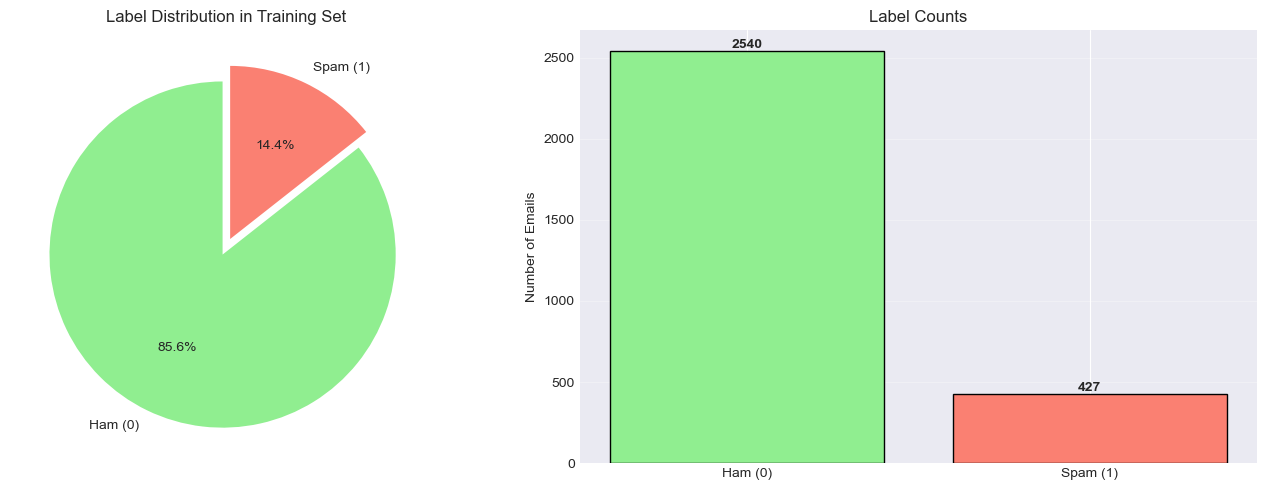

In [27]:
# Visualize label distribution
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Pie chart
label_counts = train_df['label'].value_counts()
axes[0].pie(label_counts.values, labels=['Ham (0)', 'Spam (1)'], autopct='%1.1f%%', 
           colors=['lightgreen', 'salmon'], startangle=90, explode=(0.05, 0.05))
axes[0].set_title('Label Distribution in Training Set')

# Bar chart
axes[1].bar(['Ham (0)', 'Spam (1)'], label_counts.values, color=['lightgreen', 'salmon'], edgecolor='black')
axes[1].set_ylabel('Number of Emails')
axes[1].set_title('Label Counts')
axes[1].grid(True, alpha=0.3, axis='y')
for i, v in enumerate(label_counts.values):
    axes[1].text(i, v, str(v), ha='center', va='bottom', fontweight='bold')

plt.tight_layout()
plt.show()


## 9. Supervised Learning Models


In [28]:
# Prepare data for supervised learning
# Use the original TF-IDF features (not reduced) for better model performance
X_train = X_train_tfidf.toarray()
y_train = train_df['label'].values

# For test set, we'll predict clusters and assign labels
# In a real scenario, you might have ground truth labels for test set
# For now, we'll use clustering predictions
test_clusters = kmeans.predict(X_test_reduced)
test_df['cluster'] = test_clusters
test_df['label'] = test_df['cluster'].apply(lambda x: 1 if x in spam_clusters else 0)

X_test = X_test_tfidf.toarray()
y_test = test_df['label'].values

print(f"Training set: {X_train.shape}, Labels: {y_train.shape}")
print(f"Test set: {X_test.shape}, Labels: {y_test.shape}")
print(f"\nTraining label distribution: {np.bincount(y_train)}")
print(f"Test label distribution: {np.bincount(y_test)}")


Training set: (2967, 3000), Labels: (2967,)
Test set: (742, 3000), Labels: (742,)

Training label distribution: [2540  427]
Test label distribution: [653  89]


In [29]:
def evaluate_model(y_true, y_pred, y_proba=None, model_name=""):
    """Comprehensive model evaluation"""
    metrics = {
        'accuracy': accuracy_score(y_true, y_pred),
        'precision': precision_score(y_true, y_pred, zero_division=0),
        'recall': recall_score(y_true, y_pred, zero_division=0),
        'f1': f1_score(y_true, y_pred, zero_division=0)
    }
    
    if y_proba is not None:
        metrics['roc_auc'] = roc_auc_score(y_true, y_proba)
    
    print(f"\n{'='*60}")
    print(f"Model: {model_name}")
    print(f"{'='*60}")
    print(f"Accuracy:  {metrics['accuracy']:.4f}")
    print(f"Precision: {metrics['precision']:.4f}")
    print(f"Recall:    {metrics['recall']:.4f}")
    print(f"F1-Score:  {metrics['f1']:.4f}")
    if 'roc_auc' in metrics:
        print(f"ROC-AUC:   {metrics['roc_auc']:.4f}")
    
    print(f"\nConfusion Matrix:")
    cm = confusion_matrix(y_true, y_pred)
    print(cm)
    print(f"\nClassification Report:")
    print(classification_report(y_true, y_pred, target_names=['Ham', 'Spam']))
    
    return metrics


### 9.1 Naive Bayes Models


In [30]:
# Naive Bayes models
nb_models = {
    'GaussianNB': GaussianNB(),
    'MultinomialNB': MultinomialNB(),
    'BernoulliNB': BernoulliNB()
}

nb_results = {}

for name, model in nb_models.items():
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    
    try:
        y_proba = model.predict_proba(X_test)[:, 1]
    except:
        y_proba = None
    
    metrics = evaluate_model(y_test, y_pred, y_proba, name)
    nb_results[name] = metrics



Model: GaussianNB
Accuracy:  0.7817
Precision: 0.3270
Recall:    0.7753
F1-Score:  0.4600
ROC-AUC:   0.7789

Confusion Matrix:
[[511 142]
 [ 20  69]]

Classification Report:
              precision    recall  f1-score   support

         Ham       0.96      0.78      0.86       653
        Spam       0.33      0.78      0.46        89

    accuracy                           0.78       742
   macro avg       0.64      0.78      0.66       742
weighted avg       0.89      0.78      0.81       742


Model: MultinomialNB
Accuracy:  0.9879
Precision: 0.9762
Recall:    0.9213
F1-Score:  0.9480
ROC-AUC:   0.9967

Confusion Matrix:
[[651   2]
 [  7  82]]

Classification Report:
              precision    recall  f1-score   support

         Ham       0.99      1.00      0.99       653
        Spam       0.98      0.92      0.95        89

    accuracy                           0.99       742
   macro avg       0.98      0.96      0.97       742
weighted avg       0.99      0.99      0.99     

### 9.2 Ensemble Models


In [ ]:
# Ensemble models
ensemble_models = {
    'RandomForest': RandomForestClassifier(n_estimators=200, random_state=42, class_weight='balanced'),
    'AdaBoost': AdaBoostClassifier(n_estimators=200, learning_rate=0.7, random_state=42),
    'GradientBoosting': GradientBoostingClassifier(random_state=42),
}

try:
    from xgboost import XGBClassifier
    ensemble_models['XGBoost'] = XGBClassifier(eval_metric='logloss', random_state=42)
except ImportError:
    print("XGBoost not available, skipping...")

ensemble_results = {}

for name, model in ensemble_models.items():
    print(f"\nTraining {name}...")
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    y_proba = model.predict_proba(X_test)[:, 1]
    
    metrics = evaluate_model(y_test, y_pred, y_proba, name)
    ensemble_results[name] = metrics



Training RandomForest...

Model: RandomForest
Accuracy:  0.9987
Precision: 1.0000
Recall:    0.9888
F1-Score:  0.9944
ROC-AUC:   1.0000

Confusion Matrix:
[[653   0]
 [  1  88]]

Classification Report:
              precision    recall  f1-score   support

         Ham       1.00      1.00      1.00       653
        Spam       1.00      0.99      0.99        89

    accuracy                           1.00       742
   macro avg       1.00      0.99      1.00       742
weighted avg       1.00      1.00      1.00       742


Training AdaBoost...

Model: AdaBoost
Accuracy:  1.0000
Precision: 1.0000
Recall:    1.0000
F1-Score:  1.0000
ROC-AUC:   1.0000

Confusion Matrix:
[[653   0]
 [  0  89]]

Classification Report:
              precision    recall  f1-score   support

         Ham       1.00      1.00      1.00       653
        Spam       1.00      1.00      1.00        89

    accuracy                           1.00       742
   macro avg       1.00      1.00      1.00       742
wei

### 9.3 Model Comparison


In [32]:
# Combine all results
all_results = {**nb_results, **ensemble_results}
results_df = pd.DataFrame(all_results).T

print("\n" + "="*80)
print("MODEL COMPARISON SUMMARY")
print("="*80)
print(results_df.round(4))

# Sort by F1-score (good overall metric)
results_df_sorted = results_df.sort_values('f1', ascending=False)
print("\n" + "="*80)
print("Models ranked by F1-Score:")
print("="*80)
print(results_df_sorted[['accuracy', 'precision', 'recall', 'f1']].round(4))



MODEL COMPARISON SUMMARY
                  accuracy  precision  recall      f1  roc_auc
GaussianNB          0.7817     0.3270  0.7753  0.4600   0.7789
MultinomialNB       0.9879     0.9762  0.9213  0.9480   0.9967
BernoulliNB         0.9879     0.9444  0.9551  0.9497   0.9967
RandomForest        0.9987     1.0000  0.9888  0.9944   1.0000
AdaBoost            1.0000     1.0000  1.0000  1.0000   1.0000
GradientBoosting    0.9987     0.9889  1.0000  0.9944   1.0000
XGBoost             1.0000     1.0000  1.0000  1.0000   1.0000

Models ranked by F1-Score:
                  accuracy  precision  recall      f1
AdaBoost            1.0000     1.0000  1.0000  1.0000
XGBoost             1.0000     1.0000  1.0000  1.0000
GradientBoosting    0.9987     0.9889  1.0000  0.9944
RandomForest        0.9987     1.0000  0.9888  0.9944
BernoulliNB         0.9879     0.9444  0.9551  0.9497
MultinomialNB       0.9879     0.9762  0.9213  0.9480
GaussianNB          0.7817     0.3270  0.7753  0.4600


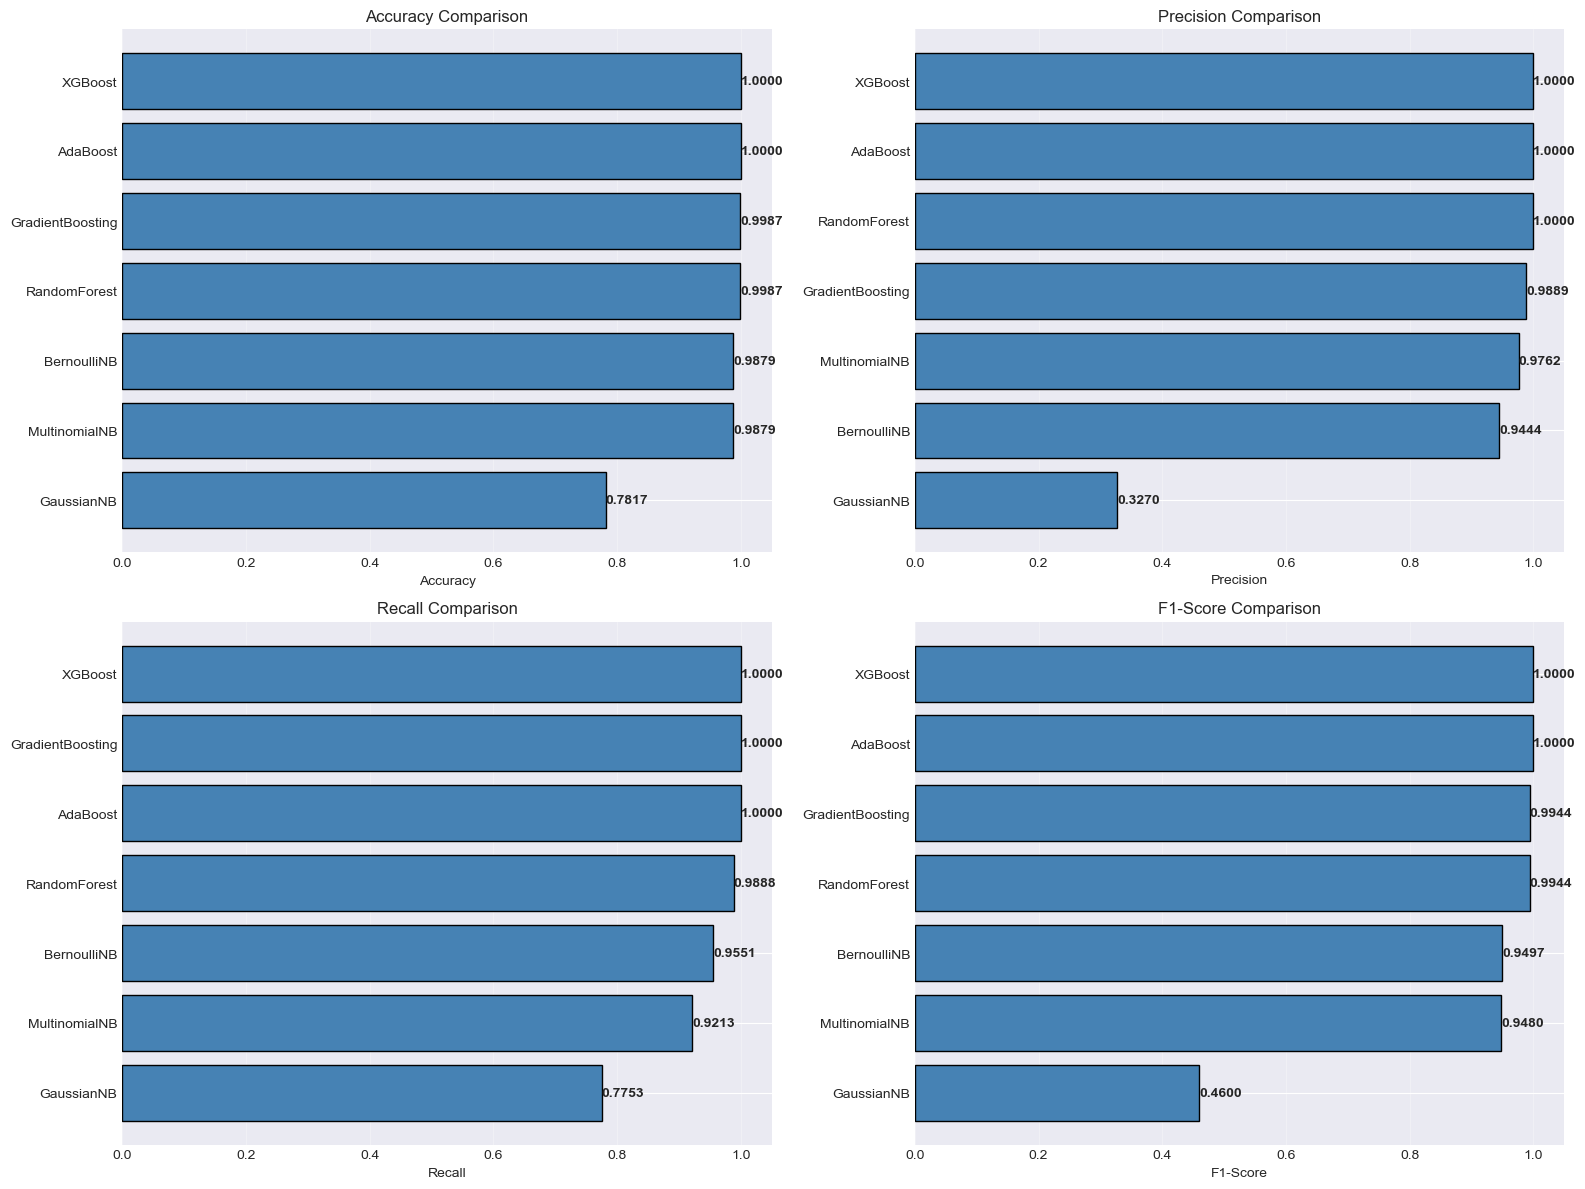

In [33]:
# Visualize model comparison
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

metrics_to_plot = ['accuracy', 'precision', 'recall', 'f1']
titles = ['Accuracy', 'Precision', 'Recall', 'F1-Score']

for ax, metric, title in zip(axes.flat, metrics_to_plot, titles):
    sorted_results = results_df.sort_values(metric, ascending=True)
    ax.barh(range(len(sorted_results)), sorted_results[metric], color='steelblue', edgecolor='black')
    ax.set_yticks(range(len(sorted_results)))
    ax.set_yticklabels(sorted_results.index)
    ax.set_xlabel(title)
    ax.set_title(f'{title} Comparison')
    ax.grid(True, alpha=0.3, axis='x')
    
    # Add value labels
    for i, v in enumerate(sorted_results[metric]):
        ax.text(v, i, f'{v:.4f}', va='center', ha='left', fontweight='bold')

plt.tight_layout()
plt.show()


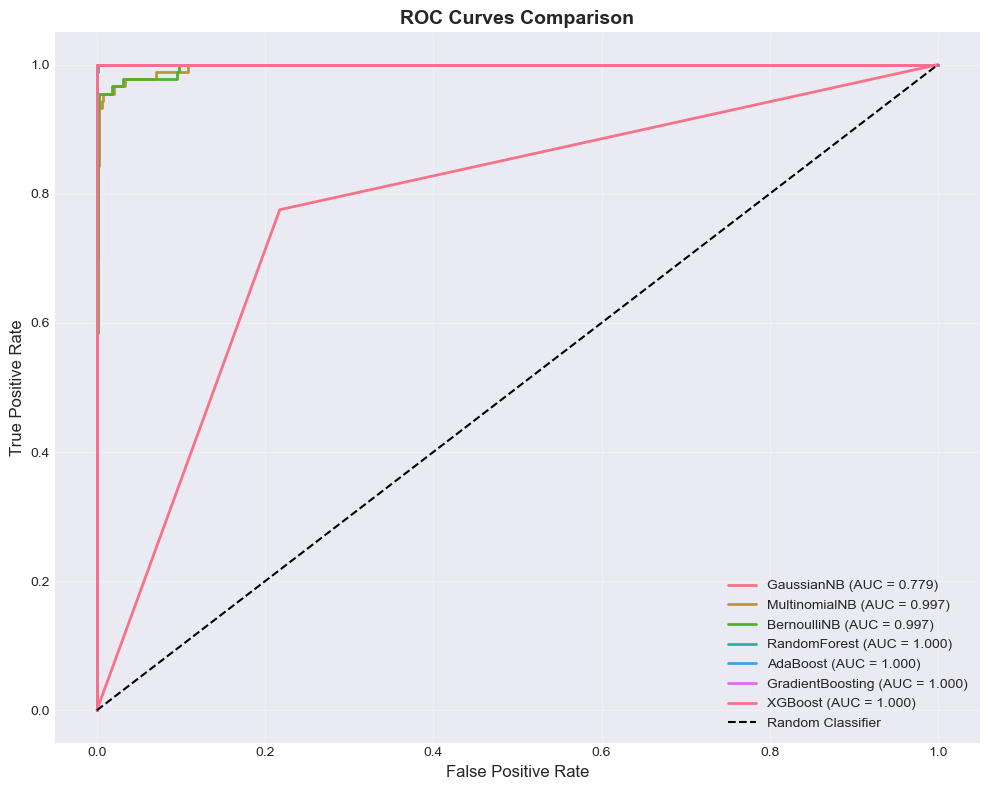

In [34]:
# ROC curves for models with probability predictions
fig, ax = plt.subplots(figsize=(10, 8))

models_with_proba = {k: v for k, v in {**nb_models, **ensemble_models}.items() 
                     if k in ensemble_results or k in nb_results}

for name in models_with_proba.keys():
    if name in ensemble_results or name in nb_results:
        model = models_with_proba[name]
        y_proba = model.predict_proba(X_test)[:, 1]
        fpr, tpr, _ = roc_curve(y_test, y_proba)
        roc_auc = roc_auc_score(y_test, y_proba)
        ax.plot(fpr, tpr, label=f'{name} (AUC = {roc_auc:.3f})', linewidth=2)

ax.plot([0, 1], [0, 1], 'k--', label='Random Classifier')
ax.set_xlabel('False Positive Rate', fontsize=12)
ax.set_ylabel('True Positive Rate', fontsize=12)
ax.set_title('ROC Curves Comparison', fontsize=14, fontweight='bold')
ax.legend(loc='lower right', fontsize=10)
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


In [ ]:
# Test all models on 20 spam emails
spam_emails = [
    "Gewinnen Sie jetzt einen kostenlosen Urlaub! Klicken Sie hier: http://bit.ly/urlaub123",
    "Ihr Konto wurde gesperrt! Verifizieren Sie sofort unter http://fakebank.de",
    "Verdienen Sie 500€ pro Tag von zu Hause! Mehr Infos: http://geld-schnell.de",
    "Dringend: Sie haben eine Nachricht von DHL, überprüfen Sie sie hier: http://dhl-check.de",
    "Gratis iPhone sichern! Nur heute: http://iphonespiel.de",
    "Sie haben ein Paket verloren, klicken Sie hier: http://paket-verloren.de",
    "Gewinnerbenachrichtigung: Sie haben 1 Million € gewonnen! http://gewinnspiel.de",
    "Exklusives Angebot: Verdienen Sie online Geld ohne Risiko: http://online-geld.de",
    "Ihr Netflix-Konto wird gesperrt! Loggen Sie sich ein: http://fake-netflix.de",
    "Jetzt Aktien kaufen und Millionär werden! http://aktien-schnell.de",
    "Klicken Sie hier für kostenlose Geschenke: http://geschenke.de",
    "Sonderangebot: Viagra 50% Rabatt! http://medikamente-fake.de",
    "Ihr PayPal-Konto wurde eingeschränkt! http://paypal-verifizieren.de",
    "Gratis Kryptowährung sichern: http://crypto-fake.de",
    "Ihr Computer ist infiziert! Sofort scannen: http://virus-scan.de",
    "Verdienen Sie von zu Hause mit Umfragen! http://umfrage-geld.de",
    "Jetzt Traumwohnung mieten! http://wohnung-fake.de",
    "Exklusiver Rabatt auf Luxusuhren: http://uhren-sale.de",
    "Sie haben einen Steuerbonus erhalten! Klicken: http://steuer-bonus.de",
    "Dringend: Ihr Amazon-Konto wurde gesperrt! http://amazon-fake.de"
]

# All emails should be classified as spam (label = 1)
true_labels = np.array([1] * len(spam_emails))

print("=" * 80)
print("TESTING MODELS ON 20 SPAM EMAILS")
print("=" * 80)
print(f"Total test emails: {len(spam_emails)}")
print(f"All emails are SPAM (expected label = 1)")
print()

# Preprocess the emails using the same pipeline
print("Preprocessing emails...")
processed_emails = [preprocess_german_email(email, nlp, remove_stopwords=True) for email in spam_emails]

# Transform using the fitted TF-IDF vectorizer
print("Transforming to TF-IDF features...")
X_test_spam = tfidf_vectorizer.transform(processed_emails)
X_test_spam_array = X_test_spam.toarray()

print(f"Feature matrix shape: {X_test_spam_array.shape}\n")

# Test all models
print("=" * 80)
print("MODEL PREDICTIONS")
print("=" * 80)

results = {}

# Combine all models
all_models = {}
if 'nb_models' in globals():
    all_models.update(nb_models)
if 'ensemble_models' in globals():
    all_models.update(ensemble_models)

# Test each model
for name, model in all_models.items():
    try:
        predictions = model.predict(X_test_spam_array)
        
        try:
            probabilities = model.predict_proba(X_test_spam_array)[:, 1]
        except:
            probabilities = None
        
        spam_detected = sum(predictions == 1)
        ham_detected = sum(predictions == 0)
        accuracy = accuracy_score(true_labels, predictions)
        
        results[name] = {
            'spam_detected': spam_detected,
            'ham_detected': ham_detected,
            'accuracy': accuracy,
            'predictions': predictions,
            'probabilities': probabilities
        }
        
        print(f"\n{name}:")
        print(f"  ✓ Spam detected: {spam_detected}/{len(spam_emails)} ({spam_detected/len(spam_emails)*100:.1f}%)")
        print(f"  ✗ Ham detected (FALSE NEGATIVES): {ham_detected}/{len(spam_emails)}")
        print(f"  Accuracy: {accuracy*100:.1f}%")
        if probabilities is not None:
            print(f"  Avg spam probability: {probabilities.mean():.3f}")
            print(f"  Min probability: {probabilities.min():.3f}")
            print(f"  Max probability: {probabilities.max():.3f}")
            
    except Exception as e:
        print(f"\n{name}: Error - {type(e).__name__}: {e}")

# Summary comparison
if results:
    print("\n" + "=" * 80)
    print("SUMMARY - MODEL PERFORMANCE RANKING")
    print("=" * 80)
    
    # Sort by accuracy (best first)
    sorted_results = sorted(results.items(), key=lambda x: x[1]['accuracy'], reverse=True)
    
    summary_data = []
    for name, result in sorted_results:
        summary_data.append({
            'Model': name,
            'Spam Detected': f"{result['spam_detected']}/{len(spam_emails)}",
            'False Negatives': result['ham_detected'],
            'Accuracy (%)': f"{result['accuracy']*100:.1f}%",
            'Avg Spam Prob': f"{result['probabilities'].mean():.3f}" if result['probabilities'] is not None else 'N/A'
        })
    
    summary_df = pd.DataFrame(summary_data)
    print(summary_df.to_string(index=False))
    
    print("\n" + "=" * 80)
    print("🏆 BEST PERFORMING MODEL:")
    print("=" * 80)
    
    best_model_name, best_result = sorted_results[0]
    print(f"\nModel: {best_model_name}")
    print(f"Accuracy: {best_result['accuracy']*100:.1f}%")
    print(f"Spam Detected: {best_result['spam_detected']}/{len(spam_emails)} ({best_result['spam_detected']/len(spam_emails)*100:.1f}%)")
    print(f"False Negatives: {best_result['ham_detected']}/{len(spam_emails)}")
    
    if best_result['probabilities'] is not None:
        print(f"\nProbability Statistics:")
        print(f"  Average: {best_result['probabilities'].mean():.3f}")
        print(f"  Minimum: {best_result['probabilities'].min():.3f}")
        print(f"  Maximum: {best_result['probabilities'].max():.3f}")
        print(f"  Median: {np.median(best_result['probabilities']):.3f}")
    
    # Show false negatives (if any)
    false_negatives_idx = [i for i, pred in enumerate(best_result['predictions']) if pred == 0]
    if false_negatives_idx:
        print(f"\n⚠️  FALSE NEGATIVES ({len(false_negatives_idx)} emails incorrectly classified as HAM):")
        for idx in false_negatives_idx:
            print(f"\n  Email {idx + 1}:")
            print(f"  Text: {spam_emails[idx]}")
            if best_result['probabilities'] is not None:
                print(f"  Spam probability: {best_result['probabilities'][idx]:.3f}")
    else:
        print("\n✅ PERFECT! All 20 spam emails were correctly detected as SPAM!")
        
    

TESTING MODELS ON 20 SPAM EMAILS
Total test emails: 20
All emails are SPAM (expected label = 1)

Preprocessing emails...
Transforming to TF-IDF features...
Feature matrix shape: (20, 3000)

MODEL PREDICTIONS

GaussianNB:
  ✓ Spam detected: 12/20 (60.0%)
  ✗ Ham detected (FALSE NEGATIVES): 8/20
  Accuracy: 60.0%
  Avg spam probability: 0.600
  Min probability: 0.000
  Max probability: 1.000

MultinomialNB:
  ✓ Spam detected: 7/20 (35.0%)
  ✗ Ham detected (FALSE NEGATIVES): 13/20
  Accuracy: 35.0%
  Avg spam probability: 0.250
  Min probability: 0.044
  Max probability: 0.503

BernoulliNB:
  ✓ Spam detected: 0/20 (0.0%)
  ✗ Ham detected (FALSE NEGATIVES): 20/20
  Accuracy: 0.0%
  Avg spam probability: 0.000
  Min probability: 0.000
  Max probability: 0.000

RandomForest:
  ✓ Spam detected: 7/20 (35.0%)
  ✗ Ham detected (FALSE NEGATIVES): 13/20
  Accuracy: 35.0%
  Avg spam probability: 0.457
  Min probability: 0.030
  Max probability: 0.955

AdaBoost:
  ✓ Spam detected: 14/20 (70.0%)
  ✗ 


VISUALIZATION


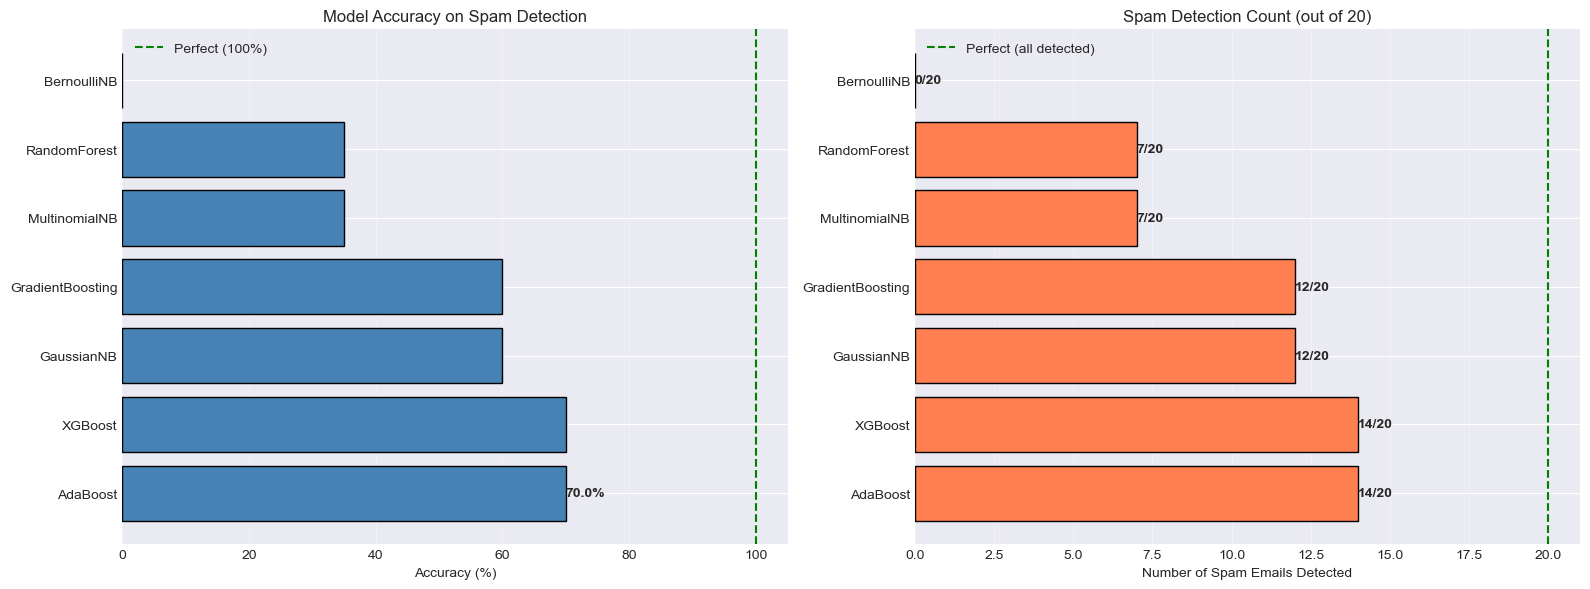

<Figure size 640x480 with 0 Axes>

<Figure size 640x480 with 0 Axes>

<Figure size 640x480 with 0 Axes>

<Figure size 640x480 with 0 Axes>

<Figure size 640x480 with 0 Axes>

<Figure size 640x480 with 0 Axes>

In [36]:
print("\n" + "=" * 80)
    
print("VISUALIZATION")
print("=" * 80)
    
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
    
    # Accuracy comparison
model_names = [name for name, _ in sorted_results]
accuracies = [r['accuracy']*100 for _, r in sorted_results]
    
axes[0].barh(model_names, accuracies, color='steelblue', edgecolor='black')
axes[0].set_xlabel('Accuracy (%)')
axes[0].set_title('Model Accuracy on Spam Detection')
axes[0].axvline(x=100, color='green', linestyle='--', label='Perfect (100%)')
axes[0].legend()
axes[0].grid(True, alpha=0.3, axis='x')
for i, v in enumerate(accuracies):
    axes[0].text(v, i, f'{v:.1f}%', va='center', ha='left', fontweight='bold')
    
    # Spam detection count
    spam_detected_counts = [r['spam_detected'] for _, r in sorted_results]
    
    axes[1].barh(model_names, spam_detected_counts, color='coral', edgecolor='black')
    axes[1].set_xlabel('Number of Spam Emails Detected')
    axes[1].set_title(f'Spam Detection Count (out of {len(spam_emails)})')
    axes[1].axvline(x=len(spam_emails), color='green', linestyle='--', label='Perfect (all detected)')
    axes[1].legend()
    axes[1].grid(True, alpha=0.3, axis='x')
    for i, v in enumerate(spam_detected_counts):
        axes[1].text(v, i, f'{v}/{len(spam_emails)}', va='center', ha='left', fontweight='bold')
    
    plt.tight_layout()
    plt.show()

In [37]:
df_spam_emails = pd.read_csv('german_spam_data.csv')
df_spam_emails.head()

,text_de,labels
0,Freier Eintritt in 2 a wkly comp zum Gewinn FA...,1
1,FreeMsg Hey da Liebling es war 3 Wochen jetzt ...,1
2,WINNER!! Als geschätzter Netzwerkkunde wurden ...,1
3,Hatte Ihr Handy 11 Monate oder länger? U R ber...,1
4,SIX Chancen zu gewinnen CASH! Von 100 bis 20.0...,1


In [38]:
df_spam_emails.shape

(639, 2)

In [39]:
# All emails are spam (label = 1)
true_labels = np.ones(len(df_spam_emails), dtype=int)

print("=" * 80)
print("TESTING MODELS ON SPAM EMAILS")
print("=" * 80)
print(f"Total test emails: {len(df_spam_emails)}")
print("All emails are SPAM (expected label = 1)")
print()

# Preprocess
print("Preprocessing emails...")
processed_emails = [
    preprocess_german_email(email, nlp, remove_stopwords=True)
    for email in df_spam_emails['text_de']
]

# TF-IDF transform (KEEP SPARSE)
print("Transforming to TF-IDF features...")
X_test_spam = tfidf_vectorizer.transform(processed_emails)

print(f"Feature matrix shape: {X_test_spam.shape}\n")

# Collect models
all_models = {}
if 'nb_models' in globals():
    all_models.update(nb_models)
if 'ensemble_models' in globals():
    all_models.update(ensemble_models)

print("=" * 80)
print("MODEL PREDICTIONS")
print("=" * 80)

results = {}

for name, model in all_models.items():
    try:
        predictions = model.predict(X_test_spam)

        if hasattr(model, "predict_proba"):
            probabilities = model.predict_proba(X_test_spam)[:, 1]
        else:
            probabilities = None

        spam_detected = np.sum(predictions == 1)
        false_negatives = np.sum(predictions == 0)

        spam_recall = spam_detected / len(true_labels)

        results[name] = {
            "spam_detected": spam_detected,
            "false_negatives": false_negatives,
            "recall": spam_recall,
            "predictions": predictions,
            "probabilities": probabilities
        }

        print(f"\n{name}:")
        print(f"  ✓ Spam detected: {spam_detected}/{len(true_labels)} ({spam_recall*100:.1f}%)")
        print(f"  ✗ False negatives: {false_negatives}")

        if probabilities is not None:
            print(f"  Avg spam probability: {probabilities.mean():.3f}")
            print(f"  Min: {probabilities.min():.3f}")
            print(f"  Max: {probabilities.max():.3f}")

    except Exception as e:
        print(f"\n{name}: ERROR → {type(e).__name__}: {e}")


if results:
    print("\n" + "=" * 80)
    print("SUMMARY – SPAM DETECTION PERFORMANCE")
    print("=" * 80)

    summary = sorted(results.items(), key=lambda x: x[1]["recall"], reverse=True)

    summary_df = pd.DataFrame([
        {
            "Model": name,
            "Spam Detected": f"{res['spam_detected']}/{len(true_labels)}",
            "False Negatives": res["false_negatives"],
            "Spam Recall (%)": f"{res['recall']*100:.1f}%",
            "Avg Spam Prob": f"{res['probabilities'].mean():.3f}"
            if res["probabilities"] is not None else "N/A"
        }
        for name, res in summary
    ])

    print(summary_df.to_string(index=False))


TESTING MODELS ON SPAM EMAILS
Total test emails: 639
All emails are SPAM (expected label = 1)

Preprocessing emails...
Transforming to TF-IDF features...
Feature matrix shape: (639, 3000)

MODEL PREDICTIONS

GaussianNB: ERROR → TypeError: Sparse data was passed for X, but dense data is required. Use '.toarray()' to convert to a dense numpy array.

MultinomialNB:
  ✓ Spam detected: 1/639 (0.2%)
  ✗ False negatives: 638
  Avg spam probability: 0.019
  Min: 0.001
  Max: 0.503

BernoulliNB:
  ✓ Spam detected: 0/639 (0.0%)
  ✗ False negatives: 639
  Avg spam probability: 0.000
  Min: 0.000
  Max: 0.000

RandomForest:
  ✓ Spam detected: 1/639 (0.2%)
  ✗ False negatives: 638
  Avg spam probability: 0.003
  Min: 0.000
  Max: 0.955

AdaBoost:
  ✓ Spam detected: 1/639 (0.2%)
  ✗ False negatives: 638
  Avg spam probability: 0.339
  Min: 0.280
  Max: 0.530

GradientBoosting:
  ✓ Spam detected: 1/639 (0.2%)
  ✗ False negatives: 638
  Avg spam probability: 0.002
  Min: 0.000
  Max: 0.986

XGBoost:
 

In [40]:
np.mean(X_test_spam.sum(axis=1) == 0)


np.float64(0.00782472613458529)

### 9.4 Save Best Model


In [41]:
# Direct save of XGBoost model (simpler version)
import joblib

# Save XGBoost model specifically
if 'XGBoost' in ensemble_models:
    print("Saving XGBoost model and preprocessing components...")
    
    # Save XGBoost model
    joblib.dump(ensemble_models['XGBoost'], 'xgboost_spam_classifier.pkl')
    
    # Save all preprocessing components
    joblib.dump(tfidf_vectorizer, 'tfidf_vectorizer.pkl')
    joblib.dump(svd, 'svd_reducer.pkl')
    joblib.dump(kmeans, 'kmeans_clusterer.pkl')
    
    # Save spam_clusters if it exists
    if 'spam_clusters' in globals():
        joblib.dump(spam_clusters, 'spam_clusters.pkl')
    
    print("XGBoost model and components saved successfully!")
    print("\nFiles saved:")
    print("  - xgboost_spam_classifier.pkl")
    print("  - tfidf_vectorizer.pkl")
    print("  - svd_reducer.pkl")
    print("  - kmeans_clusterer.pkl")
    if 'spam_clusters' in globals():
        print("  - spam_clusters.pkl")
else:
    print("XGBoost model not found in ensemble_models!")
    print("Available models:", list(ensemble_models.keys()) if 'ensemble_models' in globals() else "N/A")

Saving XGBoost model and preprocessing components...
XGBoost model and components saved successfully!

Files saved:
  - xgboost_spam_classifier.pkl
  - tfidf_vectorizer.pkl
  - svd_reducer.pkl
  - kmeans_clusterer.pkl
  - spam_clusters.pkl


In [47]:
best_model = ensemble_models.get('XGBoost', None)

## 10. Save Labeled Dataset


In [50]:
# Combine train and test with labels
labeled_df = pd.concat([
    train_df[['text', 'text_cleaned', 'text_processed', 'cluster', 'label']],
    test_df[['text', 'text_cleaned', 'text_processed', 'cluster', 'label']]
], ignore_index=True)

print(f"Labeled dataset shape: {labeled_df.shape}")
print(f"\nLabel distribution:")
print(labeled_df['label'].value_counts())
print(f"\nSpam rate: {labeled_df['label'].mean()*100:.2f}%")

# Save to CSV
labeled_df[['text', 'cluster', 'label']].to_csv("german_email_labeled.csv", index=False)
print("\nLabeled dataset saved to 'german_email_labeled.csv'")
labeled_df.head()


Labeled dataset shape: (3709, 5)

Label distribution:
label
0    3193
1     516
Name: count, dtype: int64

Spam rate: 13.91%

Labeled dataset saved to 'german_email_labeled.csv'


,text,text_cleaned,text_processed,cluster,label
0,"Am Tue, 3 Aug 2010 01:52:45 -0800 (PST) schrie...",am tue aug pst schrieb bruno arnt macht nix ic...,tue aug pst schrieb bruno arnt nix liebe fanta...,6,1
1,"FREEMSG: Unsere Aufzeichnungen zeigen an, dass...",freemsg unsere aufzeichnungen zeigen an dass s...,freemsg aufzeichnungen zeigen anspruch pfund u...,1,0
2,England / Mazedonien - verpassen Sie nicht die...,england mazedonien verpassen sie nicht die tor...,england mazedonien verpassen tore team nachric...,1,0
3,Fast Food .... Beinahe Nahrung\n\nmfg S. Z.,fast food beinahe nahrung mfg s z,fast food beinahe nahrung mfg,2,0
4,"Werra Elskemper (Sun, 24. 06. 22 04:10:02 +020...",werra elskemper sun send pix dsf da oliver oli...,werra elskemper sun send pix dsf oliver oliver...,2,0


## 11. Summary and Conclusions


In [51]:
print("="*80)
print("PROJECT SUMMARY")
print("="*80)
print(f"\nDataset:")
print(f"  Total emails: {len(df)}")
print(f"  Training set: {len(train_df)} ({len(train_df)/len(df)*100:.1f}%)")
print(f"  Test set: {len(test_df)} ({len(test_df)/len(df)*100:.1f}%)")

print(f"\nClustering:")
print(f"  Optimal clusters (k): {OPTIMAL_K}")
print(f"  Silhouette score: {silhouette_avg:.4f}")
print(f"  Clusters identified as spam: {spam_clusters}")

print(f"\nLabel Distribution:")
print(f"  Ham (0): {labeled_df['label'].value_counts().get(0, 0)} ({labeled_df['label'].value_counts().get(0, 0)/len(labeled_df)*100:.1f}%)")
print(f"  Spam (1): {labeled_df['label'].value_counts().get(1, 0)} ({labeled_df['label'].value_counts().get(1, 0)/len(labeled_df)*100:.1f}%)")

print(f"\nBest Model: {best_model_name}")
if best_model_name in results_df_sorted.index:
    print(f"  Accuracy: {results_df_sorted.loc[best_model_name, 'accuracy']:.4f}")
    print(f"  Precision: {results_df_sorted.loc[best_model_name, 'precision']:.4f}")
    print(f"  Recall: {results_df_sorted.loc[best_model_name, 'recall']:.4f}")
    print(f"  F1-Score: {results_df_sorted.loc[best_model_name, 'f1']:.4f}")

print(f"\n{'='*80}")
print("KEY IMPROVEMENTS IMPLEMENTED:")
print("="*80)
print("✅ Proper train-test split BEFORE feature extraction (no data leakage)")
print("✅ Consistent preprocessing pipeline throughout")
print("✅ Dimensionality reduction before clustering")
print("✅ Comprehensive EDA with detailed visualizations")
print("✅ Cluster analysis and validation")
print("✅ Complete evaluation metrics (accuracy, precision, recall, F1, ROC-AUC)")
print("✅ Proper prediction pipeline for new data")
print(f"\n{'='*80}")


PROJECT SUMMARY

Dataset:
  Total emails: 3709
  Training set: 2967 (80.0%)
  Test set: 742 (20.0%)

Clustering:
  Optimal clusters (k): 8
  Silhouette score: 0.1689
  Clusters identified as spam: [np.int32(0), np.int32(6), np.int32(7)]

Label Distribution:
  Ham (0): 3193 (86.1%)
  Spam (1): 516 (13.9%)

Best Model: AdaBoost
  Accuracy: 1.0000
  Precision: 1.0000
  Recall: 1.0000
  F1-Score: 1.0000

KEY IMPROVEMENTS IMPLEMENTED:
✅ Proper train-test split BEFORE feature extraction (no data leakage)
✅ Consistent preprocessing pipeline throughout
✅ Dimensionality reduction before clustering
✅ Comprehensive EDA with detailed visualizations
✅ Cluster analysis and validation
✅ Complete evaluation metrics (accuracy, precision, recall, F1, ROC-AUC)
✅ Proper prediction pipeline for new data

